# Comprehensive Global Stock Market Research
## Factor-Based Analysis Across 5 Major Markets

**Markets Covered**: China, Europe, Japan, Korea, United States

**Analysis Components**
1. Factor Performance Analysis
2. Sector Analysis
3. Cross-Country Comparison
4. Market Interpretation & Insights

---
## Setup and Data Loading

In [1]:
import configparser

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

from openai import http_client

warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Color palette for countries
COUNTRY_COLORS = {
    'china': '#E63946',
    'europe': '#457B9D',
    'japan': '#2A9D8F',
    'korea': '#E9C46A',
    'us': '#264653'
}

# Factor colors
FACTOR_COLORS = {
    'BM': '#E63946',
    'HML': '#F4A261',
    'SMB': '#2A9D8F',
    'MOM': '#264653',
    'OP': '#8338EC',
    'INV': '#06D6A0',
    'REV': '#118AB2'
}

# Base path
BASE_PATH = Path('.')
COUNTRIES = ['us', 'europe', 'japan', 'china', 'korea']

print("Setup complete. Loading data...")

Setup complete. Loading data...


In [2]:
# GICS Sector mapping
SECTOR_NAMES = {
    '10': 'Energy',
    '15': 'Materials',
    '20': 'Industrials',
    '25': 'Consumer Disc.',
    '30': 'Consumer Staples',
    '35': 'Health Care',
    '40': 'Financials',
    '45': 'Info Tech',
    '50': 'Comm. Services',
    '55': 'Utilities',
    '60': 'Real Estate'
}

In [3]:
# Data containers
data = {
    'total_ER': {}, # whole univers's equity expected returns
    'beta': {}, # whole universe's equity factor exposure
    'factor_hs': {}, # historical factor returns
    'factor_hs_clipped': {}, # clipped historical factor returns(recent 52 weeks, normalized to 100)
    'factor_ts': {}, # historical factor expected returns
    'factor_ts_clipped': {}, # clipped historical factor expected returns(recent 52 weeks, normalized to 100)
    'index_ts': {}, # historical index expected returns
    'index_ts_clipped': {}, # clipped historical index expected returns(recent 52 weeks, normalized to 100)
    'sector_ts': {}, # historical sector expected returns
    'sector_ts_clipped': {}, # clipped historical sector expected returns(recent 52 weeks, normalized to 100)
    'industry_ts' : {}, # historical industry expected returns
    'industry_ts_clipped': {}, # clipped historical industry expected returns(recent 52 weeks, normalized to 100)
    'factor_ER': {}, # factor expected returns for most recent month
    'index_ER': {}, # index expected returns for most recent month
    'sector_ER': {}, # sector expected returns for most recent month
    'industry_ER': {}, # industry expected returns for most recent month
    'size_ER': {}, # size quintile expected returns for most recent month
    'top_bot': {}, # top and bottom 10 stocks by expected return
}

def clip_ts(df, periods=52):
    """Clip time series to the last 'periods' entries and normalize to 100"""
    clipped = df[-periods:]
    clipped = (clipped / clipped.iloc[0]) * 100
    return clipped

# Load all data
for country in COUNTRIES:
    country_path = BASE_PATH / country

    # Load each file type
    data['total_ER'][country] = pd.read_csv(country_path / 'total_ER.csv', index_col=0, dtype={'sector':str})
    data['beta'][country] = pd.read_csv(country_path / 'beta.csv', index_col=0, dtype={'sector':str, 'industry':str})

    # historical time series of factor index
    data['factor_hs'][country] = pd.read_csv(country_path / 'factor_hs.csv', index_col=0, parse_dates=True)
    data['factor_hs_clipped'][country] = clip_ts(data['factor_hs'][country])
    # time series of factor index's expected return index
    data['factor_ts'][country] = pd.read_csv(country_path / 'factor_ts.csv', index_col=0, parse_dates=True)
    data['factor_ts_clipped'][country] = clip_ts(data['factor_ts'][country])
    # time series of country index's expected return index
    data['index_ts'][country] = pd.read_csv(country_path / 'index_ts.csv', index_col=0, parse_dates=True)
    data['index_ts_clipped'][country] = clip_ts(data['index_ts'][country])
    # time series of sector index's expected return index
    data['sector_ts'][country] = pd.read_csv(country_path / 'sector_ts.csv', index_col=0, parse_dates=True)
    data['sector_ts_clipped'][country] = clip_ts(data['sector_ts'][country])
    # time series of industry index's expected return index
    data['industry_ts'][country] = pd.read_csv(country_path / 'industry_ts.csv', index_col=0, parse_dates=True)
    data['industry_ts_clipped'][country] = clip_ts(data['industry_ts'][country])

    data['factor_ER'][country] = pd.read_csv(country_path / 'factor_ER.csv')
    data['index_ER'][country] = pd.read_csv(country_path / 'index_ER.csv')
    data['sector_ER'][country] = pd.read_csv(country_path / 'sector_ER.csv', dtype={'sector':str})
    data['industry_ER'][country] = pd.read_csv(country_path / 'industry_ER.csv', dtype={'industry':str})

    data['size_ER'][country] = pd.read_csv(country_path / 'size_ER.csv')
    data['top_bot'][country] = pd.read_csv(country_path / 'ERtop+bot10.csv', dtype={'sector':str})

print("Data loaded successfully!")
print(f"\nCountries: {COUNTRIES}")
print(f"\nStock counts by market:")
for country in COUNTRIES:
    print(f"  {country.upper()}: {len(data['total_ER'][country]):,} stocks")

Data loaded successfully!

Countries: ['us', 'europe', 'japan', 'china', 'korea']

Stock counts by market:
  US: 2,985 stocks
  EUROPE: 598 stocks
  JAPAN: 493 stocks
  CHINA: 572 stocks
  KOREA: 485 stocks


In [4]:
# NORMALIZATION FUNCTIONS FOR CROSS-COUNTRY COMPARISON
# Since factor models have different scales across countries, we need to
# normalize values before making cross-country comparisons.

def zscore_normalize(series):
    """Convert to z-scores (mean=0, std=1)"""
    return (series - series.mean()) / series.std()

def normalize(er, ts, er_ind:str, er_col:str, ts_col:str=None):
    """Normalize ER values using z-score based on time series data"""
    er_with_index = er.set_index(er_ind, inplace=False)
    er_val = er_with_index[er_col] / 100
    if ts_col is not None:
        ts_er = ts.filter(like=ts_col, axis=1)
        ts_er.columns = ts_er.columns.str.replace(ts_col, '')
    else:
        ts_er = ts
    ts_mean = ts_er.mean()
    ts_std = ts_er.std()

    data = pd.concat([er_val, ts_mean, ts_std], axis=1)
    data.columns = ['ER', 'Mean', 'Std']
    zscore = (data['ER'] - data['Mean']) / data['Std']
    zscore.name = 'ER_zscore'
    result = pd.concat([er_with_index, zscore], axis=1).dropna()

    return result

# Create normalized versions of key data
print("\n" + "="*70)
print("CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON")
print("="*70)

# Normalize ER data for each country
for country in COUNTRIES:
    # Normalize equity ERs
    total_er = data['total_ER'][country].copy()
    if 'ER' in total_er.columns:
        total_er['ER_zscore'] = zscore_normalize(total_er['ER'])
    data['total_ER'][country] = total_er

    # Normalize index ERs
    er = data['index_ER'][country].copy()
    ts = data['index_ts'][country].copy()

    data['index_ER'][country] = normalize(er, ts, 'index', 'wER', '_ER')

    # Normalize sector ERs
    er = data['sector_ER'][country].copy()
    ts = data['sector_ts'][country].copy()

    data['sector_ER'][country] = normalize(er, ts, 'sector', 'wER', '_ER')

    # Normalize industry ERs
    er = data['industry_ER'][country].copy()
    ts = data['industry_ts'][country].copy()

    data['industry_ER'][country] = normalize(er, ts, 'industry', 'wER', '_ER')

    # Normalize factor returns (relative strength within country)
    er = data['factor_ER'][country].copy()
    ts = data['factor_ts'][country].copy()
    data['factor_ER'][country] = normalize(er, ts, 'factor', 'ER', '_ER')

print("Normalization methods applied:")
print("  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons")
print("  • Note: Use normalized values for cross-country comparisons")


CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON
Normalization methods applied:
  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons
  • Note: Use normalized values for cross-country comparisons


In [5]:
# ============================================================
# LLM Commentary Helper  (web search + persistent conversation)
# Requires: pip install openai
# Set environment variable: OPENAI_API_KEY=your-key
# ============================================================
import os
import datetime
from IPython.display import display, Markdown

OPENAI_MODEL = "gpt-5.6-terra"  # change to "gpt-4o" for higher quality

_conversation_history = []

_SYSTEM_MESSAGE = {
    "role": "system",
    "content": (
        "당신은 글로벌 대형 기관투자자를 대상으로 미국, 유럽, 일본, 중국, 한국 시장의 "
        "멀티팩터 포트폴리오 전략을 수립하는 '뉴스 통합형 시니어 퀀트 전략가(News-Integrated Chief Quant Strategist)'입니다.\n\n"
        "【핵심 분석 원칙】\n"
        "1. 최신 뉴스 우선: 반드시 현재 날짜 기준 최근 2~4주 이내의 실제 시장 뉴스, 거시경제 이벤트, 정책 발표, 기업 공시를 먼저 검색하고 이를 분석의 중심으로 삼으십시오.\n"
        "2. 팩터 데이터는 보조 근거: 제공된 Z-스코어, 방향성(상승/하락) 등 팩터 데이터는 뉴스 해석을 뒷받침하는 정량적 확인 도구로만 활용하십시오. 수치를 직접 나열하는 것을 금지합니다.\n"
        "3. 이벤트-드리븐 내러티브: 모든 분석은 '어떤 사건/정책/테마가 이 팩터·섹터·종목을 움직이는가'라는 질문에 답하는 형식으로 서술하십시오.\n"
        "4. Bottom-line Up Front: 가장 중요한 뉴스 기반 투자 시그널부터 시작하고, 수치는 괄호 안에 간략히 표기하십시오.\n"
        "5. 격식체 한국어: 투자위원회(IC) 제출용 보고서에 부합하는 명사형 어미(~함, ~임, ~판단, ~권고)를 사용하십시오.\n"
        "6. 최신성 보장: 검색 시 반드시 현재 연도·월을 포함한 쿼리를 사용하여 최신 뉴스만 인용하십시오."
        " [팩터 종류] \n"
        "1. Beta(BM): 주식시장과의 민감도. 일반적으로 시가총액이 높을수록 1에 가까우므로 대형주와 유사"
        "2. Value(HML): 가치(B/P)가 낮은 저평가 종목"
        "3. Size(SMB): 시가총액이 낮은 소형주"
        "4. Investment(INV): 투자(총자산 증가율이 높은 기업)를 공격적으로 하는 기업. 설비투자, CAPEX를 공격적으로 늘리는 기업으로 생각할 수 있음"
        "5. Profitability(OP): ROE가 높은 고이익 기업"
        "6. Momentum(MOM): 최근 주가 상승 탄력(12m-1m)이 높은 기업"
        "7. Reversal(REV): 최근 하락한 주가가 크게 하락한 종목일수록 평균회귀 효과로 주가 상승 기대"
    )
}

def reset_conversation():
    global _conversation_history
    _conversation_history = []
    print("대화 기록이 초기화되었습니다.")

def llm_explain(data_str: str, prompt: str, use_search: bool = True) -> str:
    global _conversation_history
    try:
        from openai import OpenAI
        import httpx
        key = os.getenv('OPENAI_API_KEY', '')
        if not key:
            return "_LLM 해설을 사용할 수 없습니다 — `OPENAI_API_KEY` 환경 변수를 설정하세요._"

        client = OpenAI(api_key=key, http_client=httpx.Client(verify=False))
        today = datetime.date.today().isoformat()
        date_preamble = f"[오늘 날짜: {today}. 최근 2~4주 이내의 최신 뉴스를 검색하여 분석에 활용하십시오.]\n\n"
        user_message = {
            "role": "user",
            "content": date_preamble + prompt + "\n\nData:\n" + data_str
        }
        messages = [_SYSTEM_MESSAGE] + _conversation_history + [user_message]
        kwargs = dict(model=OPENAI_MODEL, input=messages)
        if use_search:
            kwargs["tools"] = [{"type": "web_search_preview"}]
        response = client.responses.create(**kwargs)
        reply = response.output_text
        _conversation_history.append(user_message)
        _conversation_history.append({"role": "assistant", "content": reply})
        return reply
    except ImportError:
        return "_`openai` 패키지가 설치되지 않았습니다 — `pip install openai`를 실행하세요._"
    except Exception as e:
        return f"_LLM 오류: {e}_"

def show_explanation(data_str: str, prompt: str, title: str = "분석 해설", use_search: bool = True):
    text = llm_explain(data_str, prompt, use_search=use_search)
    display(Markdown(f"---\n### 💬 {title}\n\n{text}\n\n---"))

reset_conversation()
print(f"LLM 헬퍼 로드 완료. 모델: {OPENAI_MODEL}")
print("대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)")
print("웹 검색: 활성화 (최신 뉴스 기반 분석)")
print("API 키:", "✓ 설정됨" if os.getenv('OPENAI_API_KEY') else "✗ 미설정 (OPENAI_API_KEY 환경 변수를 설정하세요)")

대화 기록이 초기화되었습니다.
LLM 헬퍼 로드 완료. 모델: gpt-5.6-terra
대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)
웹 검색: 활성화 (최신 뉴스 기반 분석)
API 키: ✓ 설정됨


---
## Section 1: 과거 관찰 — 팩터 역사적 행동

과거 팩터 시계열을 분석하여 현재 시장 국면을 진단합니다.

### Factor Time Series Performance

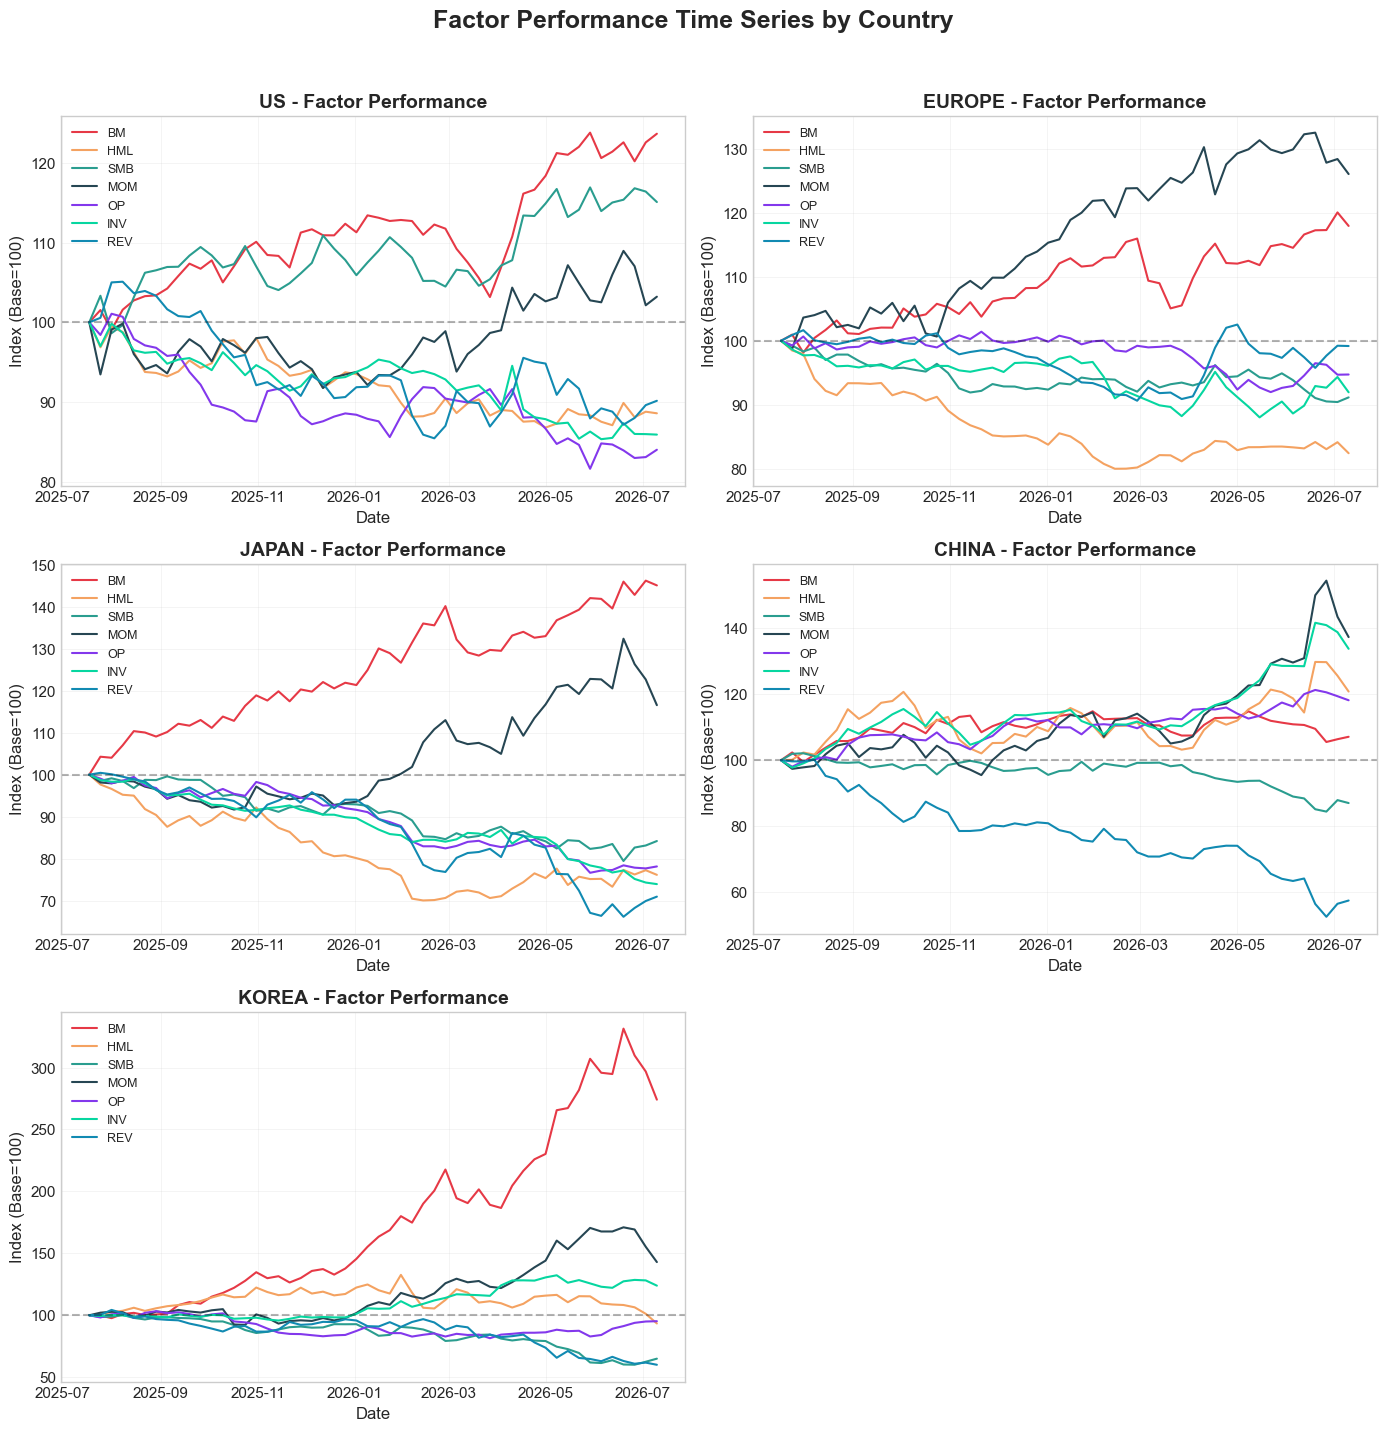

In [6]:
# Plot factor time series for each country
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_ts = data['factor_hs_clipped'][country]

    for col in factor_ts.columns:
        if col in FACTOR_COLORS:
            ax.plot(factor_ts.index, factor_ts[col], label=col,
                   color=FACTOR_COLORS.get(col, 'gray'), linewidth=1.5)

    ax.axhline(y=100, color='black', linestyle='--', alpha=0.3)
    ax.set_title(f'{country.upper()} - Factor Performance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Index (Base=100)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

plt.suptitle('Factor Performance Time Series by Country', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
# Calculate factor statistics
def calculate_factor_stats(factor_ts, factor_hs):
    """Calculate comprehensive factor statistics"""
    returns = factor_ts.pct_change().dropna()

    stats = pd.DataFrame({
        'Total Return (%)': ((factor_ts.iloc[-1] / factor_ts.iloc[0]) - 1) * 100,
        'Ann. Return (%)': returns.mean() * 52 * 100,
        'Ann. Vol (%)': returns.std() * np.sqrt(52) * 100,
        'Sharpe Ratio': (returns.mean() * 52) / (returns.std() * np.sqrt(52)),
        'Max Drawdown (%)': ((factor_ts / factor_ts.cummax()) - 1).min() * 100,
        'Max Drawdown(total) (%)': ((factor_hs / factor_hs.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    })
    return stats.round(3)

# Display factor stats for each country
for country in COUNTRIES:
    print(f"\n{'='*70}")
    print(f"{country.upper()} - FACTOR STATISTICS")
    print("="*70)
    stats = calculate_factor_stats(data['factor_hs_clipped'][country], clip_ts(data['factor_hs'][country], periods=52*5))
    display(stats.style.format('{:.1f}').background_gradient(cmap='RdYlGn', subset=['Sharpe Ratio'], axis=0))


US - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,23.7,22.5,12.6,1.8,-9.0,-25.2,0.2,-0.1
HML,-11.4,-11.8,11.0,-1.1,-13.2,-85.5,0.2,-0.4
SMB,15.1,15.3,13.6,1.1,-5.8,-42.7,-0.1,0.3
MOM,3.2,4.8,18.0,0.3,-8.2,-24.9,-0.2,0.5
OP,-16.0,-17.0,12.7,-1.3,-19.3,-29.2,0.6,0.6
INV,-14.1,-14.7,12.4,-1.2,-14.7,-39.4,0.6,4.9
REV,-9.8,-9.4,15.5,-0.6,-18.7,-40.7,0.3,0.5



EUROPE - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,17.9,17.7,13.0,1.4,-9.4,-19.9,-0.8,1.6
HML,-17.6,-19.3,8.9,-2.2,-20.0,-56.8,-0.2,0.4
SMB,-8.8,-9.2,7.4,-1.2,-9.6,-34.3,0.3,0.6
MOM,26.0,24.8,15.4,1.6,-5.7,-21.3,-0.4,0.9
OP,-5.3,-5.3,7.2,-0.7,-9.3,-17.4,-0.1,-0.4
INV,-8.1,-8.0,10.5,-0.8,-12.0,-26.3,0.2,0.2
REV,-0.8,-0.3,10.1,-0.0,-10.8,-28.1,1.1,2.0



JAPAN - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,45.1,39.2,15.2,2.6,-8.4,-14.4,-0.3,0.2
HML,-23.9,-26.4,16.6,-1.6,-30.0,-63.1,-0.0,0.8
SMB,-15.8,-16.8,12.0,-1.4,-20.6,-26.8,-0.2,0.9
MOM,16.6,17.8,21.1,0.8,-12.0,-12.9,1.0,2.0
OP,-21.9,-24.6,10.1,-2.4,-23.4,-32.1,-0.3,1.3
INV,-26.1,-30.3,8.6,-3.5,-26.1,-40.1,-0.4,1.6
REV,-29.1,-32.9,20.3,-1.6,-34.1,-48.5,-0.1,1.1



CHINA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,7.1,7.7,12.2,0.6,-8.1,-35.5,-0.3,0.2
HML,20.8,22.1,24.2,0.9,-15.4,-71.5,0.9,3.1
SMB,-13.0,-13.6,10.6,-1.3,-17.3,-33.4,0.5,1.0
MOM,37.2,35.5,25.6,1.4,-11.3,-30.7,0.8,3.7
OP,18.1,17.6,10.9,1.6,-4.7,-40.3,0.4,-0.0
INV,33.7,31.1,17.4,1.8,-9.4,-47.9,1.0,3.8
REV,-42.4,-53.2,23.7,-2.2,-47.4,-61.1,-0.4,2.1



KOREA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,174.1,110.5,37.3,3.0,-17.3,-32.3,-0.1,0.2
HML,-6.6,-2.2,31.2,-0.1,-29.6,-51.1,0.0,1.3
SMB,-35.0,-41.1,23.1,-1.8,-40.0,-67.6,-0.5,1.5
MOM,43.0,41.4,31.2,1.3,-16.4,-24.2,-0.3,1.0
OP,-4.8,-3.3,18.4,-0.2,-21.1,-22.4,-0.2,0.0
INV,23.9,23.2,16.2,1.4,-7.7,-25.6,0.5,1.3
REV,-40.0,-47.5,29.1,-1.6,-42.4,-67.4,-0.1,0.1


### Factor Correlation Analysis

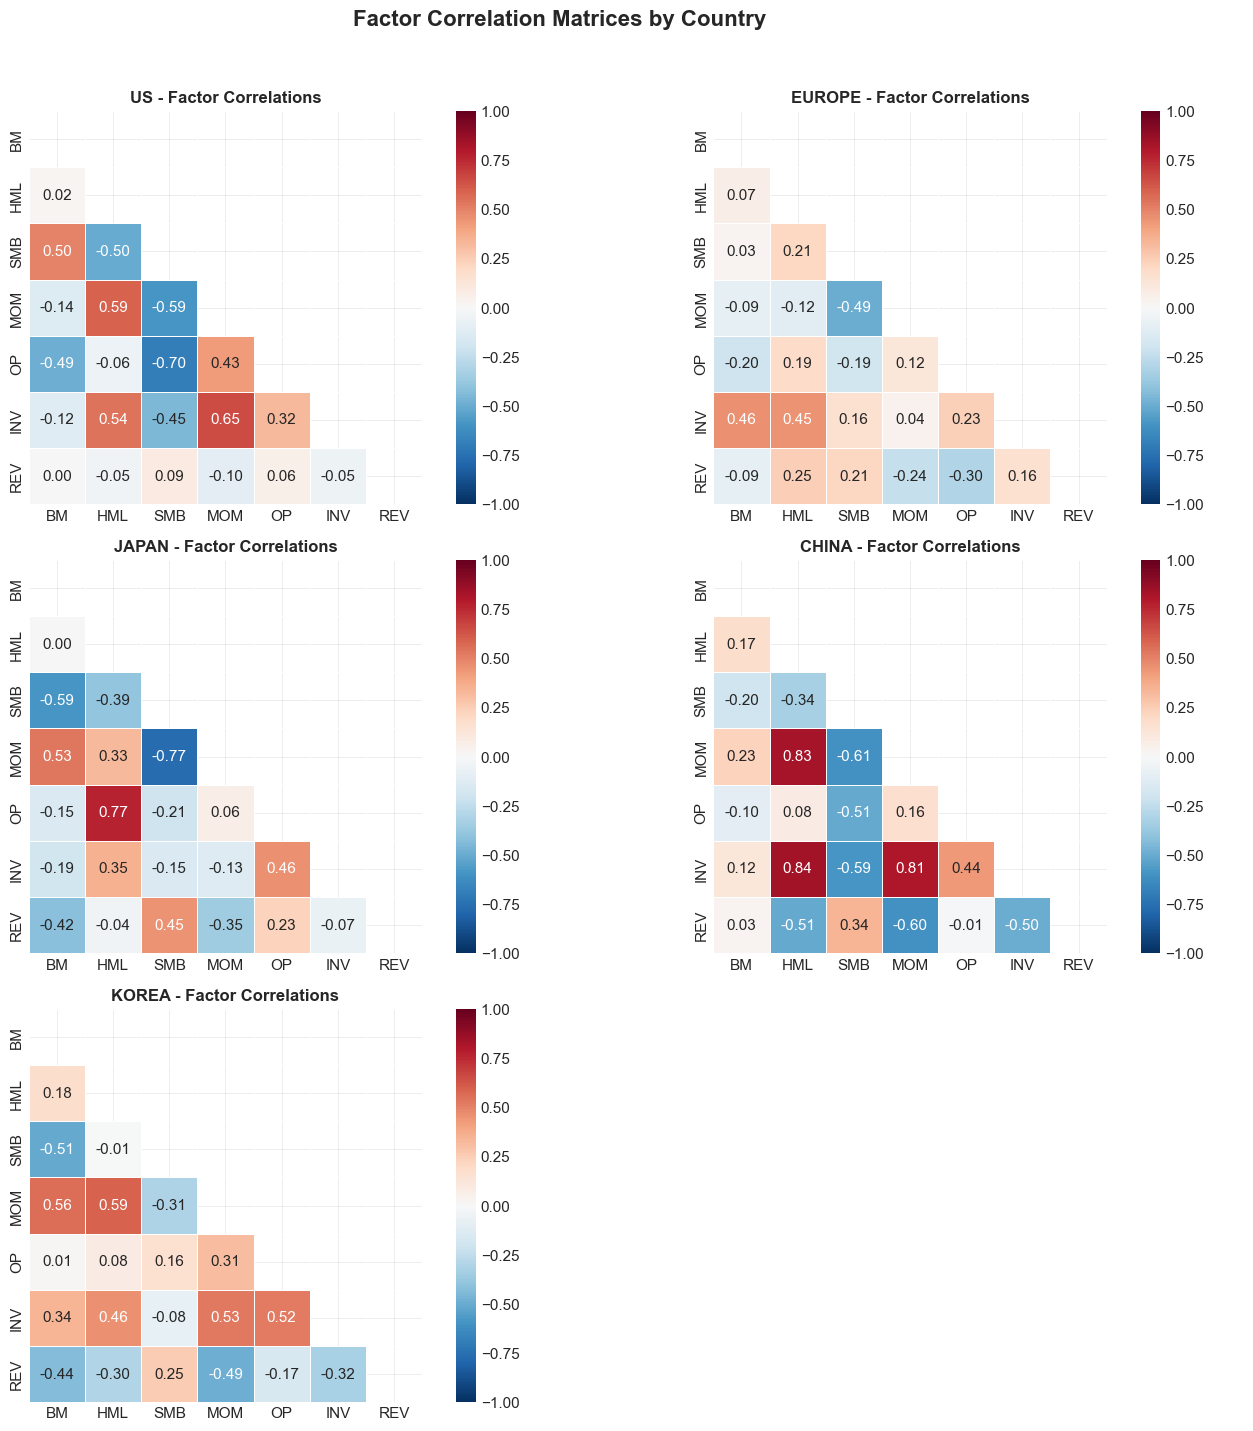

In [8]:
# Factor correlation matrices
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_returns = data['factor_hs_clipped'][country].pct_change().dropna()
    corr = factor_returns.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, ax=ax, vmin=-1, vmax=1,
                square=True, linewidths=0.5)
    ax.set_title(f'{country.upper()} - Factor Correlations', fontsize=12, fontweight='bold')

axes[5].axis('off')
plt.suptitle('Factor Correlation Matrices by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [9]:
# === Section 1 LLM: 과거 관찰 — 팩터 역사적 동인 ===
_hist_txt = f"HISTORICAL ANALYSIS — Factor Direction Summary (week ending approx. {datetime.date.today().isoformat()}\n\n"

for _c in COUNTRIES:
    _hs = data['factor_hs_clipped'][_c]
    _ret4   = (_hs.iloc[-1] / _hs.iloc[-5]  - 1) * 100 if len(_hs) >= 5  else pd.Series(dtype=float)
    _prior4 = (_hs.iloc[-5] / _hs.iloc[-9] - 1) * 100  if len(_hs) >= 9  else pd.Series(dtype=float)
    _accel  = (_ret4 - _prior4).dropna().sort_values(ascending=False)
    _top3   = list(_accel.head(3).index)
    _bot3   = list(_accel.tail(3).index)
    _hist_txt += f"{_c.upper()}: 가속 팩터={', '.join(_top3)} | 감속 팩터={', '.join(_bot3)}\n"

_hist_prompt = (
    "역할: 글로벌 퀀트 전략가. 이 섹션이 보고서의 첫 분석 단계입니다.\n\n"
    "제공된 국가별 팩터 가속/감속 방향 요약을 바탕으로 각 시장의 최신 거시경제 뉴스를 검색하십시오.\n\n"
    "검색 지시: 각 국가별로 '[국가명] 주식시장 팩터 [현재연월]' 쿼리로 최신 이벤트를 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 국가별 팩터 동향 관찰: 각 시장에서 팩터 흐름을 주도한 뉴스 이벤트/정책/테마. 팩터 방향은 괄호 안 간략 표기.\n"
    "2. 글로벌 공통 스타일 패턴: 여러 시장에서 동시에 관찰되는 스타일 로테이션과 배경 이벤트.\n"
    "3. 주목할 이상 신호: 글로벌 트렌드와 반하는 특이 시장과 그 이유.\n\n"
    "분량: A4 0.5페이지. 수치 나열 금지. 뉴스 내러티브 우선.\n"
    "※ 이 관찰은 다음 섹션(미래 신호)의 출발점으로 이어집니다."
)

show_explanation(_hist_txt, _hist_prompt, title="Section 1: 과거 관찰 — 팩터 역사적 동인 분석")


---
### 💬 Section 1: 과거 관찰 — 팩터 역사적 동인 분석

## 1. 국가별 팩터 동향 관찰

- **미국:** AI·반도체 주도의 랠리가 7월 들어 실적 검증 및 금리 경로 불확실성으로 흔들리면서, 과거 상승 주도주보다 헬스케어·산업재·금융 등으로 매수 범위가 확장되는 국면임. 이에 따라 과매도 종목의 되돌림과 밸류에이션 정상화가 부각되며 **REV·HML·INV 가속**, 반대로 대형 성장·모멘텀 및 소형주의 상대 우위는 약화되는 흐름임 (**OP·MOM·SMB 감속**). ([investing.com](https://www.investing.com/news/economy-news/investors-look-for-fed-clues-earnings-signs-as-tech-wobbles-4775428?utm_source=openai))

- **유럽:** 글로벌 기술주 조정과 동시에 NATO 정상회의의 대규모 방산 조달 및 유럽 재무장 테마가 산업재·방산 공급망으로 자금 확산을 유도함. 이는 단순 메가캡 베타보다 중소형 제조업·설비투자 수혜주 및 낙폭과대 종목을 선호하는 환경으로 연결되며 **REV·SMB·INV 가속**, 기존 수익성 프리미엄과 모멘텀은 둔화됨 (**OP·BM·MOM 감속**). ([investing.com](https://www.investing.com/news/stock-market-news/european-shares-flat-as-ai-caution-prevails-focus-on-defence-stocks-4778281?utm_source=openai))

- **일본:** 글로벌 반도체 조정 이후 은행·상사·항공·소프트웨어 등 비(非)AI 업종으로 자금이 순환하고 있음. 약세 엔화의 수출이익 지원과 장기금리 상승에 따른 금융주 재평가가 결합되면서, 대형 가치·고수익 기업 중심의 반등이 형성됨. 이에 **REV·HML·OP 가속**, AI 추세추종·중소형 및 공격적 투자 노출은 후퇴하는 양상임 (**SMB·INV·MOM 감속**). ([japan.co.jp](https://japan.co.jp/e/japan-market-desk/report-2026-07-21.html?utm_source=openai))

- **중국:** 경기 둔화와 부동산 부진 속에서 전면 부양보다 국가 주도 인프라 프로젝트 및 기술자립 투자에 정책의 무게가 실리고 있음. 최근 반도체·AI 거래의 변동성이 커지는 가운데 전통산업, 소비·금융 및 저평가 중소형주로의 로테이션이 나타나 **HML·SMB·INV 가속**으로 연결됨. 다만 수요 회복의 불확실성이 높아 **MOM·REV·OP 감속**은 지속적 이익개선보다 정책·밸류에이션 주도의 반등임을 시사함. ([ca.marketscreener.com](https://ca.marketscreener.com/news/china-bets-on-faster-state-backed-projects-to-shore-up-growth-avoid-broad-stimulus-ce7f5ed3dc81ff26?utm_source=openai))

- **한국:** 정부와 삼성전자·SK하이닉스의 대규모 AI·반도체 투자 계획이 설비투자 및 공급망 확장 기대를 견인하여 **SMB·INV·OP 가속**의 기반이 됨. 그러나 AI 투자 지속성에 대한 의문과 반도체 쏠림, 레버리지 상품 규제 이슈가 동반되며 시장 변동성이 급증했고, 추세추종 및 고베타 대형주에는 차익실현 압력이 집중됨 (**HML·BM·MOM 감속**). ([investing.com](https://www.investing.com/news/economy-news/south-korea-forecasts-2026-economic-growth-at-5year-high-on-ai-chip-boom-4789666?utm_source=openai))

## 2. 글로벌 공통 스타일 패턴

핵심 공통 신호는 **AI 메가캡 모멘텀의 약화와 가치·리버설·실물투자 테마로의 로테이션**임. 미국·유럽·일본에서 공통적으로 기술주 조정 이후 금융·산업재·방산·항공·상사 등 기존 소외 업종으로 매수 확산이 관찰됨. 특히 정책금리의 고점 장기화 가능성, 장기금리 상승 및 AI CAPEX의 수익화 검증이 고평가 성장주의 할인율 부담을 높이고, 현금흐름·자산가치·정부투자 수혜가 명확한 기업을 선호하게 만든 배경임. ([investing.com](https://www.investing.com/news/economy-news/investors-look-for-fed-clues-earnings-signs-as-tech-wobbles-4775428?utm_source=openai))

## 3. 주목할 이상 신호

**한국이 글로벌 추세와 가장 상이한 시장임.** 여타 시장이 AI 모멘텀 이탈 후 가치·방어·리버설로 이동하는 반면, 한국은 반도체 투자 확대가 INV와 OP를 지지하고 있음. 다만 동일한 AI 집중도가 급격한 지수 하락과 규제 대응으로 이어졌다는 점에서, 이는 안정적 성장 재평가라기보다 **고수익·고투자 공급망으로의 선택적 이동과 과도한 포지셔닝 청산이 공존하는 국면**으로 판단함. 향후 신호 분석에서는 한국의 투자 가속이 이익 상향으로 이어지는지, 혹은 과잉 CAPEX 위험으로 전환되는지를 우선 검증할 필요가 있음. ([investing.com](https://www.investing.com/news/stock-market-news/analysisinside-south-koreas-worldbeating-bear-market-4789669?utm_source=openai))

---

---
## Section 2: 미래 신호 — 모델의 포워드 뷰

기대수익률(Expected Return)을 통해 모델이 예측하는 미래를 확인합니다.

### Market Expected Returns

MARKET-LEVEL ANALYSIS

⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries
    because factor models have different scales/calibrations.

[1] MARKET ER - (z-score scales)
----------------------------------------------------------------------


,Weighted Mean ER (%)
US,-0.24
EUROPE,-0.21
JAPAN,-0.32
CHINA,-1.56
KOREA,-2.39



[2] CROSS-COUNTRY COMPARABLE METRICS
----------------------------------------------------------------------


,Market ER Percentile,Market ER Z-Score,% Stocks Positive ER,ER Dispersion (Q80-Q20),ER Sharpe (mean/std)
Country,,,,,
US,34.1,-0.24,61.3%,3.63,0.06
EUROPE,36.0,-0.21,54.8%,1.78,0.02
JAPAN,35.5,-0.32,39.1%,0.72,-0.02
CHINA,3.3,-1.56,25.9%,1.65,-0.06
KOREA,2.0,-2.39,13.8%,4.31,-0.16



Interpretation Guide:
  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods
  • % Stocks Positive ER: Higher = More bullish signal for the market
  • ER Sharpe: Higher = More consistent positive signal across stocks


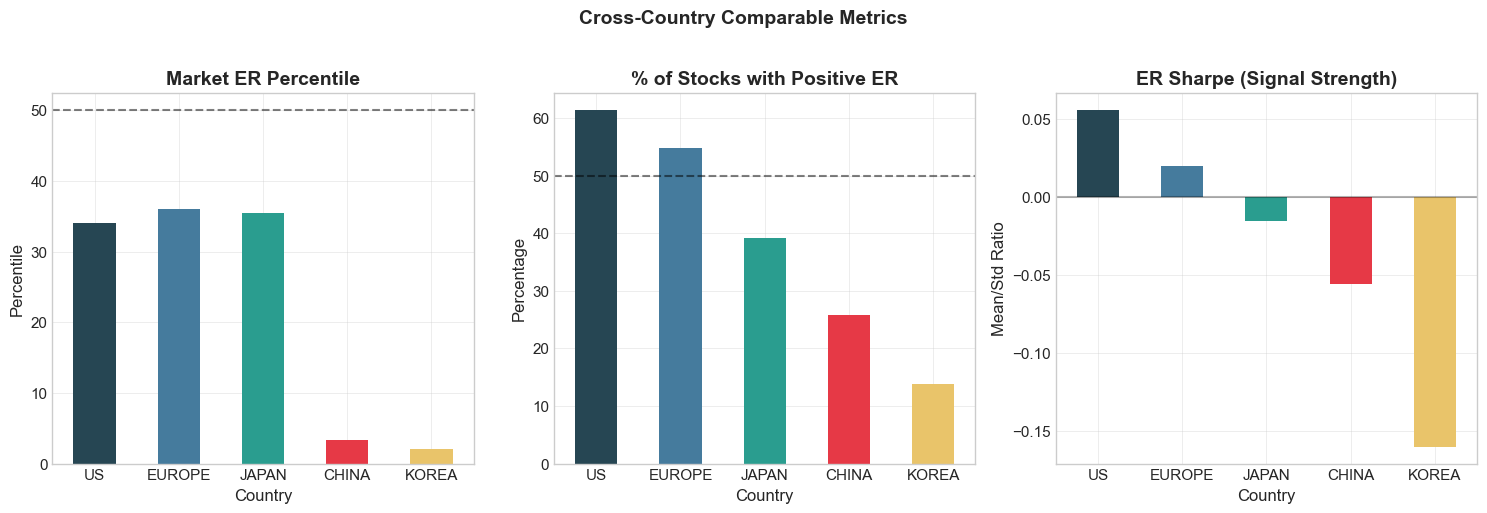

In [10]:
# Market-level expected returns comparison - WITH NORMALIZATION CONTEXT
print("="*70)
print("MARKET-LEVEL ANALYSIS")
print("="*70)
print("\n⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries")
print("    because factor models have different scales/calibrations.\n")

# Raw market ERs
market_er = {}
for country in COUNTRIES:
    wmean = data['index_ER'][country]['ER_zscore'].iloc[0]
    market_er[country.upper()] = wmean

market_er_df = pd.DataFrame([market_er], index=['Weighted Mean ER (%)']).T

print("[1] MARKET ER - (z-score scales)")
print("-"*70)
display(market_er_df.style.format('{:.2f}'))

# Calculate comparable metrics using within-country distribution
print("\n[2] CROSS-COUNTRY COMPARABLE METRICS")
print("-"*70)

comparable_metrics = []
for country in COUNTRIES:
    total_stock_er = data['total_ER'][country]
    index_total_history_er = data['index_ts'][country]['index_ER']
    index_er = data['index_ER'][country]['wER'].iloc[0]

    # What percentile is the market ER within its own distribution?
    market_percentile = (index_er/100 > index_total_history_er).mean() * 100

    # Z-score of market ER within country
    market_zscore = data['index_ER'][country]['ER_zscore'].iloc[0]

    # Stock-wise
    er_values = total_stock_er['ER'].dropna()
    sh_values = total_stock_er['Sharpe'].dropna()

    # Percentage of stocks with positive ER
    pct_positive = (er_values > 0).mean() * 100

    # Spread between top and bottom quintile
    er_spread = er_values.quantile(0.8) - er_values.quantile(0.2)

    # Sharpe-like metric: mean ER / std ER
    er_sharpe = sh_values.mean()

    comparable_metrics.append({
        'Country': country.upper(),
        'Market ER Percentile': market_percentile,
        'Market ER Z-Score': market_zscore,
        '% Stocks Positive ER': pct_positive,
        'ER Dispersion (Q80-Q20)': er_spread,
        'ER Sharpe (mean/std)': er_sharpe
    })

comparable_df = pd.DataFrame(comparable_metrics).set_index('Country')
display(comparable_df.style.format({
    'Market ER Percentile': '{:.1f}',
    'Market ER Z-Score': '{:.2f}',
    '% Stocks Positive ER': '{:.1f}%',
    'ER Dispersion (Q80-Q20)': '{:.2f}',
    'ER Sharpe (mean/std)': '{:.2f}'
}).background_gradient(cmap='RdYlGn', axis=0))

print("\nInterpretation Guide:")
print("  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods")
print("  • % Stocks Positive ER: Higher = More bullish signal for the market")
print("  • ER Sharpe: Higher = More consistent positive signal across stocks")

# Bar chart of comparable metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Market Percentile
ax = axes[0]
colors = [COUNTRY_COLORS[c.lower()] for c in comparable_df.index]
comparable_df['Market ER Percentile'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('Market ER Percentile', fontweight='bold')
ax.set_ylabel('Percentile')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 2: % Positive ER
ax = axes[1]
comparable_df['% Stocks Positive ER'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('% of Stocks with Positive ER', fontweight='bold')
ax.set_ylabel('Percentage')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 3: ER Sharpe
ax = axes[2]
comparable_df['ER Sharpe (mean/std)'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('ER Sharpe (Signal Strength)', fontweight='bold')
ax.set_ylabel('Mean/Std Ratio')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cross-Country Comparable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Factor Expected Returns

In [11]:
# Create factor returns comparison table - RAW and NORMALIZED
print("="*70)
print("FACTOR RETURNS BY COUNTRY")
print("="*70)
print("    Use Z-Score for valid cross-country comparisons.\n")

# Z-Score normalized (within each country)
factor_zscore_df = pd.DataFrame()
for country in COUNTRIES:
    fr = data['factor_ER'][country]['ER_zscore']
    factor_zscore_df[country.upper()] = fr
factor_zscore_df = factor_zscore_df.T

print("\n[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)")
print("-"*70)
display(factor_zscore_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country factor comparison using z-scores
print("\n[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)")
print("-"*70)
print("Which factors are consistently strong/weak across all markets:")
factor_strength = factor_zscore_df.mean().sort_values(ascending=False)
for factor, zscore in factor_strength.items():
    strength = "STRONG ↑" if zscore > 0.5 else ("WEAK ↓" if zscore < -0.5 else "NEUTRAL →")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {factor:5}: {zscore:+.2f} {strength} {bar}")

FACTOR RETURNS BY COUNTRY
    Use Z-Score for valid cross-country comparisons.


[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)
----------------------------------------------------------------------


,BM,HML,INV,MOM,OP,SMB
US,-0.24,-0.63,-0.81,-2.50,-0.06,0.38
EUROPE,-0.21,-0.60,-0.11,-2.93,-0.53,0.22
JAPAN,-0.32,-1.24,-1.64,-0.14,-1.33,0.50
CHINA,-1.54,0.89,1.12,1.94,-1.53,-1.46
KOREA,-2.54,-2.05,-0.72,-1.45,0.92,1.68



[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)
----------------------------------------------------------------------
Which factors are consistently strong/weak across all markets:
  SMB  : +0.27 NEUTRAL → ██
  INV  : -0.43 NEUTRAL → ████
  OP   : -0.51 WEAK ↓ █████
  HML  : -0.73 WEAK ↓ ███████
  BM   : -0.97 WEAK ↓ █████████
  MOM  : -1.01 WEAK ↓ ██████████


### Factor Premium Comparison

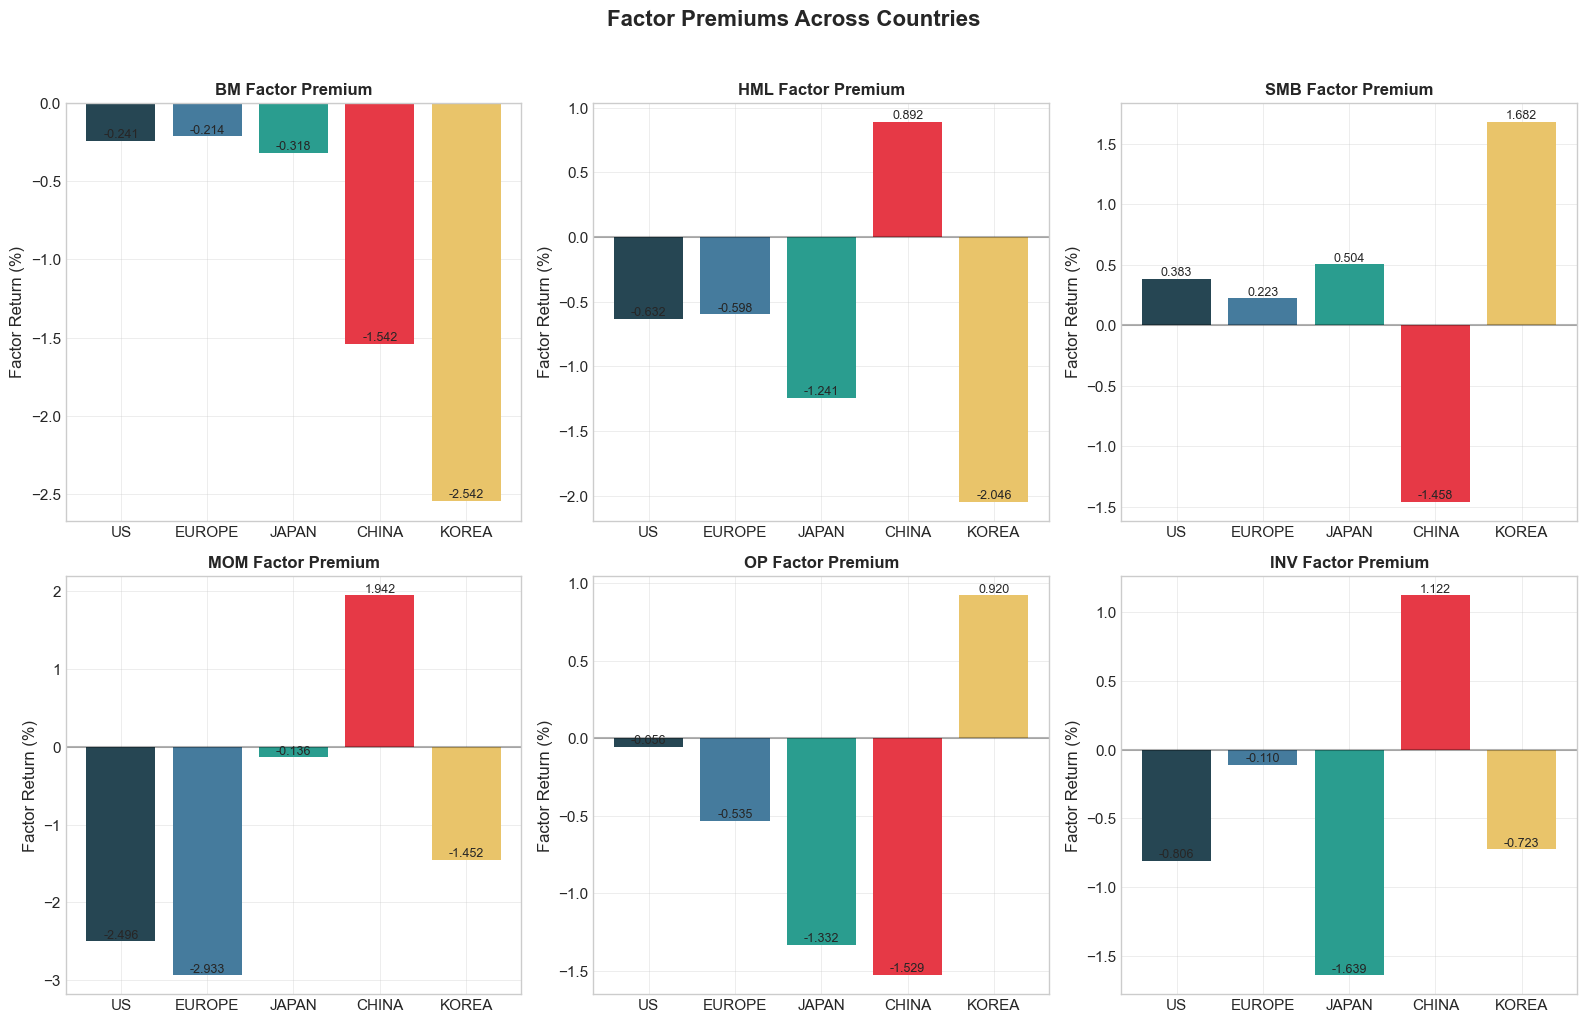

In [12]:
# Factor premium comparison across countries
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

factors = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

for idx, factor in enumerate(factors):
    ax = axes[idx]
    factor_vals = []

    for country in COUNTRIES:
        fr = data['factor_ER'][country]['ER_zscore']
        if factor in fr.index:
            factor_vals.append(fr.loc[factor])
        else:
            factor_vals.append(0)

    colors = [COUNTRY_COLORS[c] for c in COUNTRIES]
    bars = ax.bar([c.upper() for c in COUNTRIES], factor_vals, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax.set_title(f'{factor} Factor Premium', fontsize=12, fontweight='bold')
    ax.set_ylabel('Factor Return (%)')

    # Add value labels
    for bar, val in zip(bars, factor_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Factor Premiums Across Countries', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Sector Expected Returns

In [13]:
# Sector Expected Returns comparison - RAW and NORMALIZED
print("="*90)
print("SECTOR EXPECTED RETURNS BY COUNTRY")
print("="*90)
print("\n⚠️  NOTE: Raw ER values have different scales across countries.")
print("    Use Z-Score for valid cross-country sector comparisons.\n")

# Z-Score normalized sector ERs
sector_zscore_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = data['sector_ER'][country].copy()
    ind_er = ind_er.set_index('Sector')
    sector_zscore_comparison[country.upper()] = ind_er['ER_zscore']

print("\n[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)")
print("-"*70)
display(sector_zscore_comparison.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country sector analysis
print("\n[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)")
print("-"*70)
sector_global_strength = sector_zscore_comparison.mean(axis=1).sort_values(ascending=False)
for sector, zscore in sector_global_strength.items():
    strength = "OVERWEIGHT" if zscore > 0.3 else ("UNDERWEIGHT" if zscore < -0.3 else "NEUTRAL")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {str(sector):25}: {zscore:+.2f} {strength} {bar}")

SECTOR EXPECTED RETURNS BY COUNTRY

⚠️  NOTE: Raw ER values have different scales across countries.
    Use Z-Score for valid cross-country sector comparisons.


[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)
----------------------------------------------------------------------


,US,EUROPE,JAPAN,CHINA,KOREA
Sector,,,,,
Energy,0.01,-0.51,-0.04,-4.00,-0.56
Materials,-0.58,-0.46,-0.26,-2.56,-1.71
Industrials,-0.31,-0.43,-0.41,-1.78,-1.89
Consumer Discretionary,-0.55,-0.40,-0.48,-2.76,-2.14
Consumer Staples,-0.37,-0.09,-0.51,-2.26,-1.31
Health Care,0.53,-0.29,-0.52,-0.55,-1.91
Financials,0.09,0.02,-0.16,-1.57,-0.68
Information Technology,-0.32,0.22,-0.09,0.18,-2.41
Communication Services,-0.27,-0.60,-0.42,-1.61,-1.63



[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)
----------------------------------------------------------------------
  Financials               : -0.46 UNDERWEIGHT ████
  Information Technology   : -0.48 UNDERWEIGHT ████
  Health Care              : -0.55 UNDERWEIGHT █████
  Real Estate              : -0.63 UNDERWEIGHT ██████
  Communication Services   : -0.91 UNDERWEIGHT █████████
  Consumer Staples         : -0.91 UNDERWEIGHT █████████
  Industrials              : -0.96 UNDERWEIGHT █████████
  Energy                   : -1.02 UNDERWEIGHT ██████████
  Materials                : -1.12 UNDERWEIGHT ███████████
  Utilities                : -1.23 UNDERWEIGHT ████████████
  Consumer Discretionary   : -1.27 UNDERWEIGHT ████████████


In [14]:
# === Section 2 LLM: 미래 신호 — 모델의 포워드 뷰 ===
_forward_txt = f"FORWARD SIGNALS — Factor & Market Expected Returns (as of {datetime.date.today().isoformat()}\n\n"

_factors_list = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

_forward_txt += "글로벌 팩터 기대수익률 방향 (4주 기준, 국가별 상승↑/하락↓):\n"
for _f in _factors_list:
    _col = f"{_f}_ER"
    _dirs = []
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        if _col in _fts.columns and len(_fts) >= 5:
            _chg = float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5])
            _dirs.append(f"{_c.upper()}:{'↑' if _chg > 0 else '↓'}")
        else:
            _dirs.append(f"{_c.upper()}:?")
    _up = sum(1 for d in _dirs if '↑' in d)
    _consensus = "글로벌 상승" if _up >= 4 else ("글로벌 하락" if _up <= 1 else "혼조")
    _forward_txt += f"  {_f}: {' '.join(_dirs)} → {_consensus}\n"

_forward_txt += "\n국가별 시장 ER 상황:\n"
for _c in COUNTRIES:
    _mz = data['index_ER'][_c]['ER_zscore'].iloc[0]
    _top = data['factor_ER'][_c]['ER_zscore'].idxmax()
    _bot = data['factor_ER'][_c]['ER_zscore'].idxmin()
    _forward_txt += f"  {_c.upper()}: 시장ER z={_mz:.2f} | 최강팩터={_top} | 최약팩터={_bot}\n"

_forward_txt += "\n글로벌 섹터 매력도 (상위3/하위3):\n"
_sec_z = {}
for _c in COUNTRIES:
    _s_df = data['sector_ER'][_c].copy()
    if 'Sector' not in _s_df.columns and 'sector' in _s_df.columns:
        _s_df['Sector'] = _s_df['sector'].astype(str).map(SECTOR_NAMES)
    for _, _row in _s_df.iterrows():
        _sec = _row.get('Sector', '')
        if _sec and pd.notna(_sec):
            _sec_z.setdefault(str(_sec), []).append(_row.get('ER_zscore', 0))
_sec_avg = {s: sum(v)/len(v) for s, v in _sec_z.items() if v}
_sec_sorted = sorted(_sec_avg.items(), key=lambda x: x[1], reverse=True)
_forward_txt += "  상위: " + ", ".join(s for s, _ in _sec_sorted[:3]) + "\n"
_forward_txt += "  하위: " + ", ".join(s for s, _ in _sec_sorted[-3:]) + "\n"

_forward_prompt = (
    "[이전 섹션에서 확인한 팩터 동향과 뉴스 드라이버를 이어받아 분석합니다.]\n\n"
    "역할: 글로벌 퀀트 전략가. 제공되는 데이터는 '기대수익률(Expected Return)' — "
    "모델이 예측하는 미래 팩터·시장·섹터 수익률입니다.\n\n"
    "검색 지시: 각 국가별로 '[국가명] 경제 전망 [현재연월]' 쿼리로 최신 포워드 뷰 뉴스를 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 과거 추세와의 연속성/단절: 앞서 관찰한 팩터 모멘텀이 기대수익률에서도 지속되는가, "
    "아니면 모델이 반전을 예고하는가? (국가별 비교)\n"
    "2. 국가별 미래 포지셔닝: 기대수익률 기준 가장 매력적/비매력적인 시장과 그 이유 (뉴스 근거 포함).\n"
    "3. 주목할 섹터 방향: 기대수익률 상위 섹터가 강세인 배경 이벤트와 그 지속 가능성.\n\n"
    "분량: A4 0.5페이지. 수치 나열 금지.\n"
    "※ 다음 섹션에서 이 분석을 바탕으로 글로벌 통합 테제를 선언합니다."
)

show_explanation(_forward_txt, _forward_prompt, title="Section 2: 미래 신호 — 모델의 포워드 뷰 분석")


---
### 💬 Section 2: 미래 신호 — 모델의 포워드 뷰 분석

## 1. 과거 추세와의 연속성·단절

**핵심 판단은 최근의 리버설·가치 확산 국면이 향후 4주에는 ‘가치 및 투자 지속, 모멘텀의 선택적 재가동’으로 재편되는 것임.** 글로벌 기준으로 HML과 INV의 상승 기대가 유지되어, AI 과열 조정 이후 실물투자·자산가치·현금흐름을 보유한 기업으로의 자금 이동은 지속될 전망임. 다만 MOM도 상승 전환이 예상되어, 직전의 무차별적 낙폭과대 매수보다는 이익 가시성이 있는 테마의 추세 복원이 병행될 가능성이 높음.

- **미국:** 직전 REV·HML 강세와 달리 HML·MOM은 약화되고 OP·INV가 개선되는 전환 신호임. AI 수혜주의 밸류에이션 및 수익화 우려가 지속되는 가운데, 소비·고용의 둔화 조짐과 에너지발 인플레이션 불확실성이 지수 전반의 기대수익률을 제약함. 따라서 미국은 성장주 추격보다 투자집행과 이익 방어력이 검증되는 기업 선별 국면으로 판단함. ([apnews.com](https://apnews.com/article/c8ed0b54d80fe1bdaa5edcef671e6608))

- **유럽:** 과거 SMB·INV 중심의 반등은 유지되나, 향후에는 HML·SMB·MOM 우위와 INV 약화가 예상됨. 즉 방산·인프라 중심 CAPEX 기대의 일방적 확장보다, 금리 상승 환경에서도 견조한 수익을 내는 저평가 중소형주로 초점이 이동하는 구조임. 중동발 에너지 충격과 수출 둔화는 시장 전체 기대수익률의 상단을 제한함. ([ecb.europa.eu](https://www.ecb.europa.eu/press/economic-bulletin/html/eb202604.en.html))

- **일본:** HML의 연속성이 가장 뚜렷하나, 과거 OP 우위는 약화되고 SMB·MOM의 회복이 예고됨. 이는 금융·상사 등 대형 고수익 가치주의 독주에서 내수·설비투자 연관 중소형주까지 반등 범위가 넓어지는 신호임. 다만 공격적 투자 팩터의 약화는 설비투자 확대가 이미 가격에 반영되기 시작했음을 시사함. 정부는 원유 조달 다변화와 비축유 활용을 추진하는 한편 기업의 투자계획 확대를 확인하고 있음. ([www5.cao.go.jp](https://www5.cao.go.jp/keizai3/getsurei-e/2026jun.html?utm_source=openai))

- **중국:** HML·INV의 지속과 MOM 회복이 동시에 예상되나, 기존 SMB 강세는 약화되는 조합임. 정책 주도 기술·저탄소 투자와 대형 국유·핵심산업 기업으로의 선별적 집중을 의미함. 부동산 조정과 부진한 소비가 지속되는 만큼, 이번 모멘텀 회복은 광범위한 내수 회복보다 정책 수혜 성장산업 중심일 가능성이 높음. ([thedocs.worldbank.org](https://thedocs.worldbank.org/en/doc/0cb2fc6dd88d4db3816dc0433b5cb49b-0070012026/original/CEU-July-2026-EN.pdf))

- **한국:** 직전 SMB·OP 주도와 달리 향후에는 HML·MOM·BM 회복, OP·SMB 약화가 예상됨. INV만이 연속성을 보이는 구조로, 반도체 CAPEX 자체보다 AI 수요 지속성과 수익화에 대한 재평가가 핵심 변수임. 한국은행도 반도체 사이클의 성장 기여를 인정하면서도 중동 정세와 글로벌 AI 투자 지속성을 주요 불확실성으로 지목함. ([bok.or.kr](https://www.bok.or.kr/eng/bbs/E0000634/view.do?depth=400423&menuNo=400423&nttId=11062940&programType=newsDataEng&relate=Y))

## 2. 국가별 미래 포지셔닝

시장 기대수익률 기준으로는 **유럽과 미국을 상대 선호**, 일본은 중립, 중국과 한국은 보수적 접근을 권고함. 유럽은 금융·기술 중심의 실적 방어와 중소형 가치 확산 가능성이 있으나 에너지·수출 리스크를 감안한 종목선별이 필요함. 미국은 고용의 완만한 둔화와 AI 수익성 논쟁이 부담이나, 투자·수익성 개선 신호가 하방을 완충할 전망임. 반면 중국은 내수·부동산의 구조적 제약, 한국은 반도체·AI 기대 변화와 금리·포지셔닝 충격에 대한 민감도가 높아 시장 베타보다 선택적 익스포저가 적절함. IMF 역시 기술 가치사슬 편입국은 AI 수요의 수혜를 받는 반면, 전쟁·에너지 충격과 금융시장 재가격 조정이 공통 하방 위험이라고 평가함. ([imf.org](https://www.imf.org/en/publications/weo/issues/2026/07/08/world-economic-outlook-update-july-2026?cid=ca-com-homepage-WEOET2026004))

## 3. 주목할 섹터 방향

**금융·IT·헬스케어 우위**를 제시함. 금융은 장기금리 및 자금조달 비용 상승 환경에서 순이자마진과 자본환원 기대가 유효하며, 유럽에서는 은행 실적과 주가가 특히 견조했음. IT는 단기 조정에도 AI 인프라 투자와 반도체 공급망 투자라는 구조적 동력이 유지됨. 다만 과도한 밸류에이션과 AI 수요 지속성 검증이 필요하여 대형 플랫폼보다 메모리·전력·네트워킹·기업용 소프트웨어 등 실적 가시성이 높은 영역을 선호함. 헬스케어는 지정학·에너지발 거시 변동성 속 방어적 이익 가시성이 상대 강점임. 반대로 소재·유틸리티·경기소비재는 에너지 비용, 경기 둔화 및 소비 위축 위험이 겹쳐 상대 열위가 예상됨. ([ecb.europa.eu](https://www.ecb.europa.eu/press/economic-bulletin/html/eb202604.en.html))

---

---
## Section 3: 글로벌 테제 합성

과거 관찰과 미래 신호를 통합하여 하나의 시장 테제를 도출합니다.

In [15]:
# === Section 3 LLM: 글로벌 테제 합성 (NEW) ===
_thesis_txt = (
    f"GLOBAL THESIS SYNTHESIS (as of {datetime.date.today().isoformat()}\n\n"
    "앞선 두 섹션에서 다음이 확인됨:\n"
    "  • Section 1: 국가별 팩터 가속/감속 동향 및 뉴스 드라이버\n"
    "  • Section 2: 팩터·시장·섹터 기대수익률의 포워드 신호\n"
    "이 두 관찰을 통합하여 글로벌 투자 테제를 도출하십시오.\n"
)

_thesis_prompt = (
    "[지금까지 두 섹션의 분석 — 과거 팩터 행동 관찰과 미래 기대수익률 신호 — 을 통합합니다.]\n\n"
    "역할: 수석 투자전략가(CIO). 이 섹션에서 공식 시장 테제를 선언합니다.\n\n"
    "출력 구조:\n"
    "1. 글로벌 시장 테제 (1-2문장): "
    "현재 글로벌 시장은 [X 국면]에 있으며, [Y 팩터/섹터/스타일]이 유리한 환경이다. "
    "핵심 드라이버는 [Z 이벤트/정책/매크로]이다.\n"
    "2. 지역별 테제 강도: 이 테제가 가장 강하게 적용되는 시장 vs. 예외·이탈 시장 (이유 포함).\n"
    "3. 테제 유효 기간과 무효화 조건: 어떤 이벤트/지표가 발생하면 이 테제를 수정해야 하는가.\n\n"
    "분량: A4 0.5페이지.\n"
    "이 섹션은 보고서 전체의 중심 주장입니다 — 명확하고 단호하게 서술할 것. 수치 나열 금지."
)

show_explanation(_thesis_txt, _thesis_prompt, title="Section 3: 글로벌 테제 합성")


---
### 💬 Section 3: 글로벌 테제 합성

## 1. 글로벌 시장 테제

**현재 글로벌 시장은 ‘지수 베타 축소 속 가치·선별 모멘텀·전략투자 CAPEX로의 다층 로테이션’ 국면에 진입한 것으로 판단함.** 시장 전체 기대수익률은 제한적이나, 금융·IT·헬스케어 및 저평가·투자집행 역량을 갖춘 기업이 유리하며, 핵심 드라이버는 중동발 유가·인플레이션 불확실성에 따른 금리 재가격, AI 투자 수익화 검증, 그리고 안보·공급망 재편에 연동된 방산·인프라·반도체 투자 확대임. IMF는 전쟁과 기술 변화의 교차 속에서 금융시장 재평가 위험을 주요 하방 요인으로 제시하고 있으며, S&P Global 역시 유가가 글로벌 통화정책의 핵심 변수가 될 것으로 평가함. ([imf.org](https://www.imf.org/en/publications/weo/issues/2026/07/08/world-economic-outlook-update-july-2026?cid=ca-com-homepage-WEOET2026004&utm_source=openai))

## 2. 지역별 테제 강도

**테제 적용 강도는 유럽·일본에서 가장 높음.** 유럽은 방산·인프라 및 금융 중심의 가치 재평가와 중소형주 확산이 결합되는 시장이며, 수출 전망 둔화와 중동 전쟁발 변동성은 지수 추격보다 현금흐름·가격전가력·재무건전성을 보유한 종목 선별의 필요성을 높임. 일본은 장기금리 상승, 재정정책 및 공급망·방산 투자 확대 기대가 금융·상사·산업재 및 내수 중소형주로의 스타일 확산을 지지하는 환경임. ([ecb.europa.eu](https://www.ecb.europa.eu/press/economic-bulletin/html/eb202604.en.html?utm_source=openai))

**미국은 선택적 적용 시장임.** AI CAPEX는 유지되나, 반도체 및 AI 주도주의 변동성 확대와 소비 둔화 조짐으로 모멘텀 추종보다 수익성 있는 투자와 방어적 이익 성장에 초점을 둘 필요가 있음. 최근 시장 하락이 AI 수혜 반도체주 매도에 의해 확대된 점은 고평가 성장주 집중 포지션의 취약성을 확인하는 신호임. ([apnews.com](https://apnews.com/article/c8ed0b54d80fe1bdaa5edcef671e6608?utm_source=openai))

**중국과 한국은 테제의 예외·이탈 시장으로 분류함.** 중국은 가치·투자·모멘텀의 동시 개선 신호에도 부동산 및 내수 제약으로 정책 수혜 대형 핵심산업 중심의 제한적 반등 가능성이 높음. 한국은 반도체 투자와 이익 개선 기대가 유효하나, 시장 기대수익률의 상대 열위와 AI 공급망 집중도가 병존하여 시장 베타 확대보다 반도체 CAPEX의 실제 수주·마진으로 검증된 종목에 국한해야 함. ([thedocs.worldbank.org](https://thedocs.worldbank.org/en/doc/0cb2fc6dd88d4db3816dc0433b5cb49b-0070012026/original/CEU-July-2026-EN.pdf?utm_source=openai))

## 3. 테제 유효 기간과 무효화 조건

본 테제의 유효 기간은 **향후 1~2개 분기**로 판단함. 무효화 조건은 세 가지임. 첫째, 호르무즈 해협 및 중동 정세 안정으로 유가와 기대인플레이션이 빠르게 하락하여 금리 인하 기대가 재점화될 경우, 성장·장기듀레이션 모멘텀주가 다시 시장 주도권을 회복할 가능성임. 둘째, AI 인프라 투자에서 실적 상향과 수익화가 예상보다 강하게 확인될 경우, 현재의 가치 확산은 재차 메가캡 성장주 집중으로 되돌아갈 수 있음. 셋째, 유럽의 수출 둔화가 실물경기 침체로 확대되거나 중국의 부동산·소비 부진이 정책투자 효과를 상쇄할 경우, 가치·중소형·투자 팩터의 동반 강세 가정은 철회해야 함. ([spglobal.com](https://www.spglobal.com/market-intelligence/en/news-insights/research/2026/07/global-economic-outlook-july-2026?utm_source=openai))

---

---
## Section 4: 섹터·팩터 함의

확정된 테제를 기반으로 섹터 배분 방향을 도출합니다.

### Sector Factor Exposures

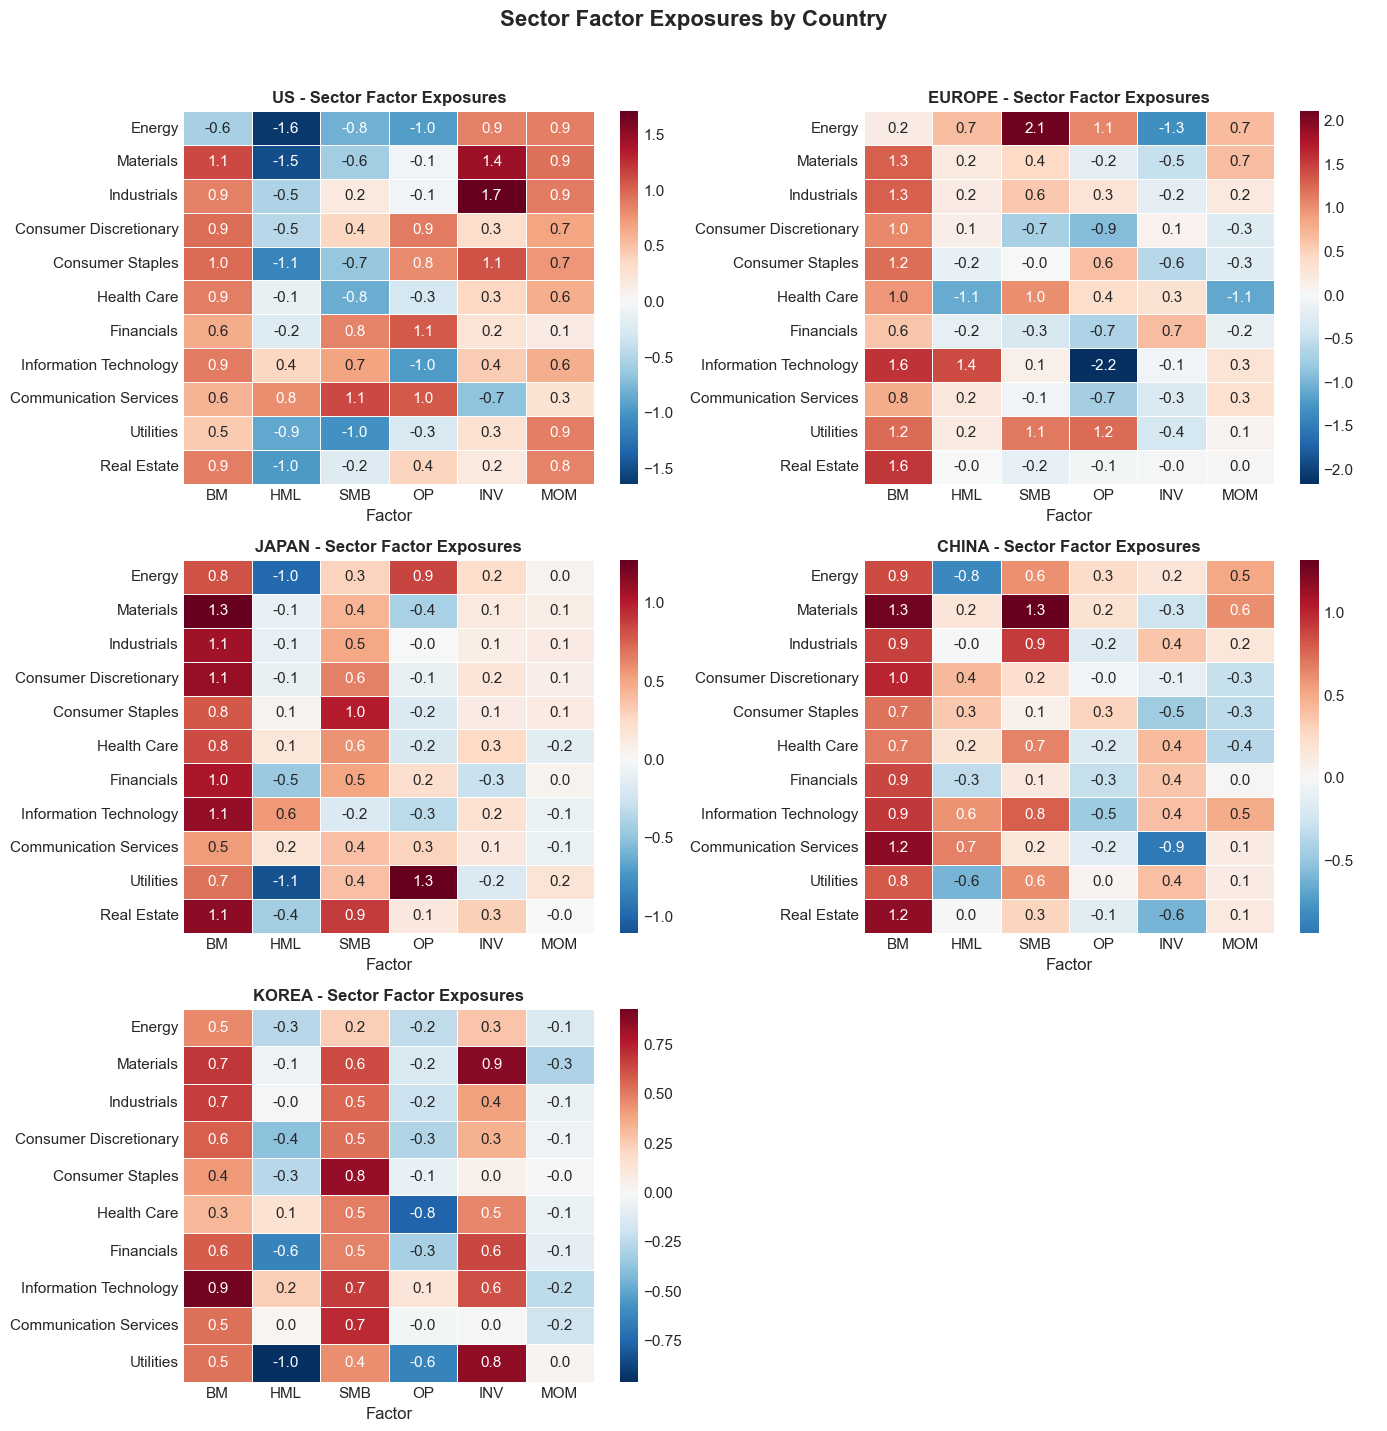

In [16]:
# Sector factor exposure heatmaps
factor_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    ind_er = data['sector_ER'][country].copy()

    # Get sector names as index
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er['Sector'] = ind_er['industry'].astype(str).map(SECTOR_NAMES)
        ind_er = ind_er.set_index('Sector')

    # Get available factor columns
    available_factors = [col for col in factor_cols if col in ind_er.columns]

    if available_factors:
        plot_data = ind_er[available_factors].dropna(how='all')
        plot_data.columns = [c.replace('beta_', '').upper() for c in plot_data.columns]

        sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='RdBu_r',
                    center=0, ax=ax, linewidths=0.5)
        ax.set_title(f'{country.upper()} - Sector Factor Exposures', fontsize=12, fontweight='bold')
        ax.set_xlabel('Factor')
        ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'No factor data available', ha='center', va='center')
        ax.set_title(f'{country.upper()}')

axes[5].axis('off')
plt.suptitle('Sector Factor Exposures by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [17]:
from itertools import islice

# === Section 4 LLM: 섹터·팩터 함의 ===
_beta_cols_map = {'BM': 'beta_bm', 'HML': 'beta_hml', 'SMB': 'beta_smb',
                  'OP': 'beta_op', 'INV': 'beta_inv', 'MOM': 'beta_mom'}

_sector_impl_txt = "FACTOR-SECTOR ALIGNMENT ANALYSIS\n\n"

_sector_impl_txt += "국가별/섹터별 팩터 정렬 점수 상세:\n"
for _c in COUNTRIES:

    _f_zscores = {}
    for _f in ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']:
        _vals = data['factor_ER'][_c]['ER_zscore'].get(_f, 0)
        _f_zscores[_f] = _vals
    _sorted_f = dict(sorted(_f_zscores.items(), key=lambda item: item[1], reverse=True))

    _strong = dict(islice(_sorted_f.items(), 2))
    _weak = dict(islice(reversed(_sorted_f.items()), 2))
    _sector_impl_txt += f"현재 강세 팩터: {', '.join(_strong) if _strong else '없음'}\n"
    _sector_impl_txt += f"현재 약세 팩터: {', '.join(_weak) if _weak else '없음'}\n\n"


    _sector_impl_txt += f"  [{_c.upper()}]\n"
    _sec_df = data['industry_ER'][_c].copy()
    if 'Sector' in _sec_df.columns:
        _sec_df = _sec_df.set_index('Sector')
    elif 'industry' in _sec_df.columns:
        _sec_df = _sec_df.set_index('industry')
    for _sec in _sec_df.index:
        _factor_details = []
        for _f, _bcol in _beta_cols_map.items():
            if _bcol in _sec_df.columns and _f in _f_zscores:
                _bval = _sec_df.loc[_sec, _bcol]
                _factor_details.append(f"{_f}:{_bval:.2f}")
        _sector_impl_txt += f"    - {_sec}: {', '.join(_factor_details)}\n"
    _sector_impl_txt += "\n"

_sector_impl_prompt = (
    "[확정된 글로벌 테제를 기반으로 섹터 배분 함의를 도출합니다.]\n\n"
    "역할: 글로벌 팩터-섹터 전략가.\n\n"
    "수혜 섹터 = 강세 팩터에 높은 베타 노출 (팩터 프리미엄 수령), "
    "역풍 섹터 = 약세 팩터에 높은 베타 노출 (팩터 드래그).\n\n"
    "출력 구조:\n"
    "1. 테제 수혜 섹터 (표): 국가 | 섹터 | 수혜 근거 (팩터-섹터 정렬 + 뉴스 촉매) — 국가별 3개씩\n"
    "2. 테제 역풍 섹터 (표): 국가 | 섹터 | 역풍 근거 — 국가별 3개씩\n"
    "3. 글로벌 오버웨이트/언더웨이트 권고: 테제에 기반한 섹터 배분 방향 요약.\n\n"
    "수치 나열 금지. 섹터 배분 관점의 핵심만 서술.\n"
    "※ 다음 섹션에서 이 섹터 방향을 구체적인 종목으로 연결합니다."
)

show_explanation(_sector_impl_txt, _sector_impl_prompt,
                 title="Section 4: 섹터·팩터 함의 — 테제 기반 섹터 배분", use_search=True)


---
### 💬 Section 4: 섹터·팩터 함의 — 테제 기반 섹터 배분

## 1. 테제 수혜 섹터

| 국가 | 섹터 | 수혜 근거: 팩터–섹터 정렬 + 뉴스 촉매 |
|---|---|---|
| 미국 | 금융서비스·소비자금융 | 소형주·수익성 노출이 높고 투자·추세추종 의존도가 낮아 **SMB·OP 우위**에 가장 정렬됨. AI 주도 기술주의 변동성 확대와 섹터 전반 실적 확산은 금융의 상대적 이익 방어력을 부각시키는 촉매임. ([apnews.com](https://apnews.com/article/c8ed0b54d80fe1bdaa5edcef671e6608?utm_source=openai)) |
| 미국 | 헬스케어 기술 | 소형·수익성 노출과 낮은 투자·모멘텀 민감도가 결합되어 방어적 성장 대안으로 유리함. AI 밸류에이션 재검증 국면에서 반복매출과 규제 진입장벽을 가진 헬스케어 IT 선호가 예상됨. ([apnews.com](https://apnews.com/article/c8ed0b54d80fe1bdaa5edcef671e6608?utm_source=openai)) |
| 미국 | 인터랙티브 미디어·소프트웨어 | SMB·OP 정렬이 양호하고, 과도한 설비투자보다 AI의 서비스형 수익화에 노출된 구조임. 단, 대형 AI 인프라 지출 수혜주와 달리 실제 이용자·광고·구독 수익으로 검증되는 기업에 한정할 필요가 있음. ([ssga.com](https://www.ssga.com/us/en/individual/insights/sector-market-perspectives-q3-2026?utm_source=openai)) |
| 유럽 | 육상운송·물류 | 소형 및 투자 팩터 노출이 높고 모멘텀·가치 의존도가 낮아 **SMB·INV 강세**에 부합함. 방산 조달, 군수 이동성 및 인프라 투자 확대가 물류·운송망의 구조적 수요를 지지함. ([consilium.europa.eu](https://www.consilium.europa.eu/en/press/press-releases/2026/06/18/european-council-conclusions-on-ukraine-and-on-european-defence-and-security/?utm_source=openai)) |
| 유럽 | IT 서비스 | 중소형 서비스 기업의 투자 확대 수혜가 예상되며, AI·국방·공공 디지털화의 수요가 결합되는 영역임. 유럽의 방위산업 투자 확대가 민간 기술·통신 인프라까지 파급될 가능성이 높음. ([consilium.europa.eu](https://www.consilium.europa.eu/en/policies/defence-numbers/?utm_source=openai)) |
| 유럽 | 자본시장·금융서비스 | SMB·INV 정렬과 낮은 모멘텀 의존도가 우호적임. 금리와 지정학 리스크가 높은 환경에서 거래·헤지·자본조달 수요가 유지되는 가운데, 유럽의 투자 확대가 금융중개 수요를 뒷받침할 전망임. ([esm.europa.eu](https://www.esm.europa.eu/press-releases/euro-area-resilience-under-strain-global-risks-intensify?utm_source=openai)) |
| 일본 | 유통 | SMB와 MOM 노출이 높고 INV·OP 민감도가 낮아 현재 팩터 체계에 적합함. 임금 인상과 고용 여건 개선이 내수 회복 및 소비 관련 중소형주의 실적 개선을 지지함. ([boj.or.jp](https://www.boj.or.jp/research/brp/rer/rera260709.htm?utm_source=openai)) |
| 일본 | 광범위 소매 | 중소형·모멘텀 노출이 높고 공격적 투자 부담이 제한적임. 기업이익과 가계소득 개선이 확인되는 가운데, AI·수출주 외의 내수 순환매 수혜가 기대됨. ([corporate.vanguard.com](https://corporate.vanguard.com/content/corporatesite/us/en/corp/vemo/vemo-japan.html?utm_source=openai)) |
| 일본 | 전문 소매 | SMB·MOM 정렬이 양호하며 설비투자 및 수익성 팩터 약세의 역풍이 상대적으로 작음. 최근 전자·은행 외 서비스 업종으로의 시장 확산 조짐도 긍정적임. ([fukoku-cm.co.jp](https://www.fukoku-cm.co.jp/english-reports/english-market-view/latest.html?utm_source=openai)) |
| 중국 | 반도체·반도체 장비 | MOM·INV 노출이 높고 수익성·시장베타 의존이 낮아 정책 주도 성장투자에 부합함. 중국의 고기술 투자와 수출이 경기 회복을 지지하고 있어 전략산업 중심의 선별적 모멘텀 지속 가능성이 있음. ([worldbank.org](https://www.worldbank.org/en/news/press-release/2026/07/07/rebalancing-growth-china-economic-update?utm_source=openai)) |
| 중국 | 에너지 장비·서비스 | 투자와 모멘텀 노출이 양호하며, 전통 성장부양보다 국가 주도 설비·에너지 투자에 연동되는 구조임. 정부채 발행과 전략투자가 신용 및 투자 활동을 지지하는 점이 촉매임. ([thedocs.worldbank.org](https://thedocs.worldbank.org/en/doc/0cb2fc6dd88d4db3816dc0433b5cb49b-0070012026/original/CEU-July-2026-EN.pdf?utm_source=openai)) |
| 중국 | 항공우주·방산 | 중소형·투자 노출이 높고 수익성 약세 부담이 상대적으로 제한됨. 기술자립과 전략산업 육성이라는 정책 방향의 직접 수혜 섹터로 판단함. ([worldbank.org](https://www.worldbank.org/en/news/press-release/2026/07/07/rebalancing-growth-china-economic-update?utm_source=openai)) |
| 한국 | 소프트웨어 | SMB·OP 노출이 높고 시장베타 및 가치 팩터 민감도가 상대적으로 낮아 현 국면의 최우선 수혜 영역임. 반도체 중심 AI 투자가 지속될 경우 기업용 소프트웨어와 AI 응용 서비스로 수요가 확산될 여지가 있음. ([bok.or.kr](https://www.bok.or.kr/eng/bbs/E0000634/view.do?depth=400423&menuNo=400423&nttId=11062940&programType=newsDataEng&relate=Y&utm_source=openai)) |
| 한국 | IT 서비스 | 소형·수익성 팩터에 정렬되면서 반도체 자체보다 AI 인프라의 서비스화·운영 수요에 노출됨. AI 투자 지속성은 리스크이나, 반도체 수출의 파급효과가 국내 성장에 기여하고 있음. ([bok.or.kr](https://www.bok.or.kr/eng/bbs/E0000634/view.do?depth=400423&menuNo=400423&nttId=11062940&programType=newsDataEng&relate=Y&utm_source=openai)) |
| 한국 | 반도체·장비 | SMB·OP 및 투자 노출이 결합된 핵심 수혜 영역임. 견조한 AI 메모리 수요와 수출이 실적을 지지하나, 지수 집중도와 변동성이 높아 대형주 추격보다 장비·부품·설계 생태계 중심 선별 접근을 권고함. ([apnews.com](https://apnews.com/article/fad756c430007b891ff275043fea1453?utm_source=openai)) |

## 2. 테제 역풍 섹터

| 국가 | 섹터 | 역풍 근거 |
|---|---|---|
| 미국 | IT 서비스 | INV·MOM 노출이 매우 높은 반면 수익성·소형주 정렬이 약함. AI CAPEX 수익화 우려와 반도체·AI 주도주 조정이 지속될 경우 멀티플 압축 위험이 큼. ([apnews.com](https://apnews.com/article/c8ed0b54d80fe1bdaa5edcef671e6608?utm_source=openai)) |
| 미국 | 에너지 장비·서비스 | 투자와 모멘텀 의존도가 높아 약세 팩터의 직접적 부담을 받음. 중동발 유가 상승은 단기 수주에는 우호적이나, 비용·금리 재상승 및 경기둔화 우려가 밸류에이션을 제약할 가능성임. ([apnews.com](https://apnews.com/article/c8ed0b54d80fe1bdaa5edcef671e6608?utm_source=openai)) |
| 미국 | 항공우주·방산 | 장기 수주 가시성에도 공격적 투자 노출이 높아 단기 팩터 환경에는 불리함. 방산 예산과 항공기 백로그는 견조하나, 고유가가 상업 항공 수요의 불확실성을 높임. ([ssga.com](https://www.ssga.com/us/en/individual/insights/sector-market-perspectives-q3-2026?utm_source=openai)) |
| 유럽 | 반도체·장비 | MOM·HML 노출이 높고 SMB·INV 정렬이 약함. 유럽의 기술주 재평가가 진행되더라도 글로벌 AI 수요의 지속성 검증 전에는 추세추종 매수의 기대보상이 제한적임. ([dje.de](https://www.dje.de/en/markets/markets/market-outlook-for-july-2026-europe-catches-up-the-us-remains-resilient/?utm_source=openai)) |
| 유럽 | 에너지 장비·서비스 | 모멘텀 및 가치 민감도가 높고 투자 노출이 낮음. 에너지 가격 충격은 매출에는 긍정적일 수 있으나 유럽 전반의 비용압력과 성장 둔화를 동반해 상대수익을 제한할 전망임. ([ecb.europa.eu](https://www.ecb.europa.eu/press/key/date/2026/html/ecb.sp260616~8076dabd2c.en.pdf?b913289d2b44e0f93aab74086be8bd2d=&utm_source=openai)) |
| 유럽 | 금속·광업 | 모멘텀 의존도가 높고 투자·수익성 정렬이 부진함. 유럽 성장 전망의 취약성과 에너지 비용 상승은 경기민감 소재 수요에 부담으로 작용함. ([spglobal.com](https://www.spglobal.com/market-intelligence/en/news-insights/research/2026/07/global-economic-outlook-july-2026?utm_source=openai)) |
| 일본 | 해운 | MOM 노출은 있으나 INV와 OP 노출이 과도하여 현 팩터 환경에서 불리함. 원유가격 상승과 중동 리스크는 운임을 지지할 수 있으나 비용·교역 불확실성도 동시에 확대함. ([corporate.vanguard.com](https://corporate.vanguard.com/content/corporatesite/us/en/corp/vemo/vemo-japan.html?utm_source=openai)) |
| 일본 | 섬유·의류·럭셔리 | 소형·모멘텀 수혜보다 투자 및 수익성 약세의 부담이 더 큰 구조임. 소비 회복은 긍정적이나, 실질소득 개선의 지속 여부가 확인되기 전까지는 선택적 접근이 필요함. ([boj.or.jp](https://www.boj.or.jp/research/brp/rer/rera260709.htm?utm_source=openai)) |
| 일본 | 부동산 개발 | 투자 팩터 노출이 높아 금리·국채 수급 불확실성에 취약함. 장기금리 상승이 재정 및 금융시장 우려로 전이될 경우 할인율 부담이 확대될 수 있음. ([japan.co.jp](https://japan.co.jp/e/japan-market-desk/report-2026-07-12.html?utm_source=openai)) |
| 중국 | 전문서비스 | 시장베타와 수익성 노출이 높지만 투자·모멘텀은 약해 정책 주도 성장 국면과의 정렬이 낮음. 부동산 조정과 신중한 소비가 지속되는 상황에서 민간 서비스 수요 회복은 후행할 가능성이 있음. ([worldbank.org](https://www.worldbank.org/en/news/press-release/2026/07/07/rebalancing-growth-china-economic-update?utm_source=openai)) |
| 중국 | 호텔·레저 | 투자·모멘텀 노출이 낮아 내수 회복 지연의 영향을 받기 쉬움. 중국 소비자의 신중한 지출 성향이 지속되는 점이 핵심 역풍임. ([worldbank.org](https://www.worldbank.org/en/news/press-release/2026/07/07/rebalancing-growth-china-economic-update?utm_source=openai)) |
| 중국 | 개인생활용품 | 수익성 의존도가 높고 투자·모멘텀 노출이 부진함. 정책 수혜가 전략산업과 수출에 집중되는 동안 소비재의 실적 회복은 상대적으로 제한될 전망임. ([thedocs.worldbank.org](https://thedocs.worldbank.org/en/doc/0cb2fc6dd88d4db3816dc0433b5cb49b-0070012026/original/CEU-July-2026-EN.pdf?utm_source=openai)) |
| 한국 | 헬스케어 서비스 | 수익성 팩터 노출이 낮아 OP 강세에 역행함. AI·반도체 중심 성장과 통화긴축 환경은 내수 서비스의 할인율 및 비용 부담을 높일 가능성이 있음. ([apnews.com](https://apnews.com/article/fad756c430007b891ff275043fea1453?utm_source=openai)) |
| 한국 | 생명과학 도구·서비스 | OP 노출이 낮고 가치 민감도가 높아 현 팩터 조합상 상대 열위임. 금리 인상과 위험선호 약화는 장기 성장 기대에 의존하는 연구장비·바이오 서비스 기업에 부담임. ([apnews.com](https://apnews.com/article/fad756c430007b891ff275043fea1453?utm_source=openai)) |
| 한국 | 전기장비 | 수익성 정렬이 약하고 시장 민감도가 높은 반면, 반도체 투자 외 설비투자 확산의 가시성은 아직 제한적임. AI 투자 지속성에 대한 불확실성이 확대될 경우 투자 사이클 민감 업종의 변동성이 커질 수 있음. ([bok.or.kr](https://www.bok.or.kr/eng/bbs/E0000634/view.do?depth=400423&menuNo=400423&nttId=11062940&programType=newsDataEng&relate=Y&utm_source=openai)) |

## 3. 글로벌 오버웨이트·언더웨이트 권고

**오버웨이트는 금융, 선별적 IT 서비스·소프트웨어, 헬스케어 기술, 유럽 물류·방산 연관 인프라, 중국 전략 반도체·에너지 장비, 한국 반도체 공급망의 중소형 수익성 기업으로 권고함.** 공통 논리는 지수 베타보다 소형주·수익성·정책 또는 전략투자 수혜가 우세한 국면이라는 점임.

**언더웨이트는 고(高)모멘텀·고투자 의존 미국 AI 인프라, 유럽 소재·에너지 장비, 일본 해운·부동산, 중국 내수 서비스, 한국 저수익성 헬스케어 서비스로 권고함.** 다만 한국 반도체는 구조적 성장 수혜와 과도한 지수 집중 위험이 공존하므로, 국가 전체 비중 확대보다 실적 가시성이 확인된 공급망 내 선별 보유가 적절함. ([bok.or.kr](https://www.bok.or.kr/eng/bbs/E0000634/view.do?depth=400423&menuNo=400423&nttId=11062940&programType=newsDataEng&relate=Y&utm_source=openai))

---

---
## Section 5: 국가별 시사점

글로벌 테제가 각 시장에서 어떻게 나타나는지, 그리고 그 안에서 가장 유망한 종목을 도출합니다.

### Top Equities by country

In [18]:
# Top 10 stocks by Expected Return for each country
print("="*90)
print("TOP 10 STOCKS BY EXPECTED RETURN (Each Country)")
print("="*90)

for country in COUNTRIES:
    print(f"\n{'-'*70}")
    print(f"{country.upper()}")
    print("-"*70)

    top_bot = data['top_bot'][country]
    top_bot['Sector'] = top_bot['sector'].map(lambda x: SECTOR_NAMES[x], na_action='ignore')
    # Get top 10 (highest ER)
    if 'ER' in top_bot.columns:
        top10 = top_bot.nlargest(10, 'ER')[['instrument', 'Name', 'Sector', 'ER', 'Vol', 'Sharpe', 'mktval']]
        top10.columns = ['ISIN', 'Name', 'Sector', 'Expected Return(%)', 'Vol(%)', 'Sharpe(X)', 'Market Cap(Local mn)']
        top10 = top10.style.format({
            'Expected Return(%)': '{:.2f}',
            'Vol(%)': '{:.2f}',
            'Sharpe(X)': '{:.2f}',
            'Market Cap(Local mn)': '{:,.0f}',
        })
        display(top10)

TOP 10 STOCKS BY EXPECTED RETURN (Each Country)

----------------------------------------------------------------------
US
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
3,US05464C1018,Axon Enterprise Inc,Industrials,10.27,19.40,0.53,"43,599"
4,US90138F1021,Twilio Inc,Info Tech,8.92,16.94,0.53,"31,151"
8,US6792951054,Okta Inc,Info Tech,8.15,16.08,0.51,"23,933"
7,US42824C1099,Hewlett Packard Enterprise Co,Info Tech,6.13,12.02,0.51,"63,997"
13,US4592001014,International Business Machines Corp,Info Tech,5.56,11.71,0.47,"269,901"
11,US4039491000,HF Sinclair Corp,Energy,5.30,10.90,0.49,"12,823"
14,US64110D1046,NetApp Inc,Info Tech,5.26,11.09,0.47,"32,927"
0,US0530151036,Automatic Data Processing Inc,Industrials,4.53,7.43,0.61,"96,562"
16,US3635761097,Arthur J. Gallagher & Co.,Financials,4.31,9.20,0.47,"65,000"
17,US3156161024,F5 Inc,Info Tech,4.09,8.78,0.47,"24,085"



----------------------------------------------------------------------
EUROPE
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
2,AT0000969985,AT & S Austria Technologie & Systemtechnik AG,Info Tech,9.68,26.63,0.36,"4,536"
5,IT0005482333,Technoprobe SpA,Info Tech,5.79,18.50,0.31,"8,644"
16,DE000A2E4K43,Delivery Hero SE,Consumer Disc.,5.75,22.47,0.26,"8,204"
4,NL0000226223,STMicroelectronics NV,Info Tech,4.34,13.54,0.32,"40,728"
6,DE0006231004,Infineon Technologies AG,Info Tech,3.86,12.41,0.31,"94,830"
9,DK0060252690,Pandora A/S,Consumer Disc.,3.75,12.92,0.29,"7,564"
1,IE0000669501,Glanbia PLC,Consumer Staples,2.97,7.83,0.38,"4,288"
11,CH1431598916,Inficon Holding AG,Info Tech,2.73,9.85,0.28,"3,076"
3,CH1216478797,DSM-Firmenich AG,Materials,2.56,7.83,0.33,"19,128"
7,LU2237380790,Allegro.eu SA,Consumer Disc.,2.48,8.28,0.30,"5,832"



----------------------------------------------------------------------
JAPAN
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
0,JP3236330001,Kioxia Holdings Corp,Info Tech,5.32,29.88,0.18,"14,460,851"
18,JP3148800000,Ibiden Co Ltd,Info Tech,1.96,23.82,0.08,"5,067,477"
3,JP3368000000,Resonac Holdings Corp,Materials,1.91,13.85,0.14,"2,951,934"
1,JP3982800009,Rohm Co Ltd,Info Tech,1.89,12.52,0.15,"1,991,454"
13,JP3888400003,Mitsui Kinzoku Co Ltd,Materials,1.76,19.68,0.09,"1,955,308"
16,JP3811000003,Fujikura Ltd,Industrials,1.63,18.46,0.09,"8,952,743"
2,JP3294460005,Inpex Corp,Energy,1.26,8.97,0.14,"2,995,069"
17,JP3571400005,Tokyo Electron Ltd,Info Tech,1.19,13.48,0.09,"33,267,302"
12,JP3921290007,Mercari Inc,Consumer Disc.,1.16,12.32,0.09,"531,167"
7,JP3695200000,NGK Insulators Ltd,Industrials,1.13,10.13,0.11,"1,954,940"



----------------------------------------------------------------------
CHINA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
2,CNE1000036B2,Yangtze Optical Fibre and Cable Joint Stock Ltd Co,Info Tech,6.49,28.44,0.23,"51,968"
0,CNE100005VF9,Yuanjie Semiconductor Technology Co Ltd,Info Tech,5.84,20.69,0.28,"128,533"
17,CNE100001XQ1,Suzhou TFC Optical Communication Co Ltd,Info Tech,5.23,28.73,0.18,"158,084"
7,CNE100002PK8,Advanced Fiber Resources Zhuhai Ltd,Info Tech,5.15,25.16,0.20,"32,995"
1,CNE100001CY9,Zhongji Innolight Co Ltd,Info Tech,4.89,20.06,0.24,"874,141"
3,CNE100002615,Eoptolink Technology Inc Ltd,Info Tech,4.88,21.99,0.22,"584,549"
4,CNE100006M90,Hua Hong Semiconductor Ltd,Info Tech,4.60,21.47,0.21,"297,235"
6,CNE100000N79,Suzhou Dongshan Precision Manufacturing Co Ltd,Info Tech,4.43,21.40,0.21,"301,680"
15,CNE100002Q09,Hangzhou Changchuan Technology Co Ltd,Info Tech,4.04,21.97,0.18,"137,807"
18,CNE100005VN3,Biwin Storage Technology Co Ltd,Info Tech,4.00,22.20,0.18,"121,055"



----------------------------------------------------------------------
KOREA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
2,KR7043260009,Sungho Electronics Corp,Info Tech,9.25,39.00,0.24,"711,347"
11,KR7347700007,Sphere Corp,Health Care,6.14,36.67,0.17,"784,318"
5,KR7322000001,HD Hyundai Energy Solutions Co Ltd,Info Tech,5.39,27.85,0.19,"592,800"
3,KR7458870003,Seers Technology Co Ltd,Health Care,5.37,25.73,0.21,"774,350"
0,KR7010950004,S-Oil Corp,Energy,4.43,16.07,0.28,"5,535,266"
13,KR7295310007,HVM Co Ltd,Materials,4.43,28.89,0.15,"282,604"
7,KR7263750002,PearlAbyss Corp,Comm. Services,4.26,22.22,0.19,"1,126,030"
10,KR7031980006,PSK Holdings Inc,Info Tech,4.14,24.11,0.17,"903,755"
9,KR7368770004,FiberPro Inc,Info Tech,3.97,22.51,0.18,"150,581"
18,KR7052020005,STCube Inc,Info Tech,3.90,28.73,0.14,"495,924"


In [19]:
# === Section 5 LLM: 국가별 시사점 (per-country loop) ===
for _c in COUNTRIES:
    _td_txt = f"TOP-DOWN ANALYSIS: {_c.upper()} (as of {datetime.date.today().isoformat()}\n\n"

    _ind_z = data['industry_ER'][_c].copy()
    if 'industry' in _ind_z.columns:
        _ind_z = _ind_z.set_index('industry')
    if 'ER_zscore' in _ind_z.columns:
        _top5_ind = _ind_z['ER_zscore'].dropna().nlargest(10)
        _td_txt += "상위 10개 산업 (ER 강세 기준):\n"
        for _ind_code, _z in _top5_ind.items():
            _td_txt += f"  Industry code {_ind_code}\n"

    _tb = data['top_bot'][_c].copy()
    _tb['SectorName'] = _tb['sector'].map(lambda x: SECTOR_NAMES.get(str(x), str(x)))
    if 'ER' in _tb.columns:
        _top10 = _tb.nlargest(20, 'ER')[['Name', 'SectorName']]
        _td_txt += "\n상위 10개 종목 (종목명 | 섹터):\n"
        for _, _row in _top10.iterrows():
            _td_txt += f"  {_row['Name']} | {_row['SectorName']}\n"

    _td_prompt = (
        f"[확정된 글로벌 테제와 섹터 배분 방향을 기반으로 {_c.upper()} 시장 시사점을 도출합니다.]\n\n"
        f"역할: {_c.upper()} 시장 전문 애널리스트.\n\n"
        f"검색 지시: '[{_c}] [상위 산업명] [{datetime.date.today().strftime('%Y %B')}]' 쿼리로, "
        f"각 상위 종목명으로 '[종목명] {datetime.date.today().year} news' 형태로 검색하십시오.\n\n"
        "출력 구조 (탑다운):\n"
        f"1. 테제의 {_c.upper()} 적용: 글로벌 테제가 이 시장에서 어떻게 강화 또는 완화되는가? 시장 특수성 설명.\n"
        "2. 수혜 산업 테마: 테제에 정렬된 상위 산업과 최신 뉴스 촉매.\n"
        "3. 컨빅션 픽 3개: 산업 테마 + 종목 뉴스가 가장 정렬된 종목. 각 투자 근거 한 문장.\n\n"
        "분량: A4 0.3페이지. 뉴스 이벤트 중심. 한국어로 작성."
    )

    show_explanation(_td_txt, _td_prompt, title=f"Section 5: {_c.upper()} 시장 시사점")


---
### 💬 Section 5: US 시장 시사점

## 1. 테제의 US 적용

**미국은 글로벌 ‘지수 베타 축소·선별 알파 확대’ 테제가 가장 엄격하게 적용되는 시장임.** 시장 기대수익률이 제한적인 가운데, AI 인프라의 무차별적 추격보다 공공안전·기업 IT 운영·보험중개처럼 **반복매출, 수익성 및 중소형 성장 노출**을 갖춘 서비스형 산업이 우위인 국면으로 판단함. AI 지출은 계속 확대되나, 기업의 실제 도입은 인프라·관리형 서비스 중심으로 진행되고 있어 순수 고CAPEX 하드웨어보다 실행·통합 수혜가 상대적으로 유리함. ([gartner.com](https://www.gartner.com/en/newsroom/press-releases/2026-05-19-gartner-forecasts-worldwide-ai-spending-to-grow-47-percent-in-2026?utm_source=openai))

## 2. 수혜 산업 테마

- **IT 서비스·전문서비스:** 기업의 AI 도입이 모델 구매보다 데이터·보안·운영 통합 수요로 전환되는 국면임.  
- **보험:** 금리·변동성 환경에서 보험중개와 리스크관리 수요가 유지되며, 직접적인 재해 손해율 리스크가 낮은 브로커를 선호함.  
- **공공안전·방산 기술:** 미국의 국방 첨단화 및 공공부문 AI·감시 인프라 수요가 보안 소프트웨어, 센서 및 지휘통제 플랫폼으로 확산되는 흐름임. 국방예산 의회 논의의 불확실성은 존재하나, 미사일방어·신기술 투자 수요는 구조적으로 유지됨. ([axios.com](https://www.axios.com/2026/07/15/lockheed-nlight-joint-laser-contract?utm_source=openai))

## 3. 컨빅션 픽 3개

- **Axon Enterprise — 공공안전 AI·클라우드:** 7월 AI 기능을 포함한 Evidence 플랫폼 업데이트와 연간 매출 가이던스 상향이 확인되어, 공공안전 디지털화의 반복매출 수혜를 가장 직접적으로 반영하는 종목으로 판단함. ([axon.com](https://www.axon.com/help/release-notes/dems/2026/07-2026.htm?utm_source=openai))  
- **Arthur J. Gallagher — 보험중개:** 7월 Med James 인수로 전문 보험중개 네트워크 확대를 지속하고 있어, 재해 손실을 직접 부담하는 보험사보다 수수료 기반 수익성 테제에 부합함. ([rttnews.com](https://www.rttnews.com/symbolsearch.aspx?symbol=AJG&utm_source=openai))  
- **Twilio — 기업 커뮤니케이션 AI 인프라:** 에이전틱 AI 시대의 고객접점 플랫폼 전환과 최근 WhatsApp·RCS 기능 확장은 기업 AI 도입의 애플리케이션·통합 수요를 흡수하는 촉매로 판단함. ([investors.twilio.com](https://investors.twilio.com/news-releases/news-release-details/twilios-next-generation-platform-infrastructure-layer-every?utm_source=openai))

---

---
### 💬 Section 5: EUROPE 시장 시사점

## 1. 테제의 EUROPE 적용

**유럽은 글로벌 테제가 가장 강하게 적용되는 시장으로 판단함.** 산업생산의 전반적 회복은 아직 미약하나, 유럽연합의 전력화·산업경쟁력 정책과 AI·방산·공급망 자립 투자가 결합되면서 지수 베타보다 **중소형 기술 제조, 디지털 인프라 및 이벤트 주도 소비 플랫폼**의 상대 알파가 확대되는 구조임. 특히 자본재 생산은 견조한 반면 중간재와 내구소비재는 부진하여, 광범위한 경기민감주 매수보다 정책·설비투자 수혜 산업에 집중할 필요가 있음. ([ec.europa.eu](https://ec.europa.eu/eurostat/en/web/products-euro-indicators/w/4-15072026-ap?utm_source=openai))

## 2. 수혜 산업 테마

- **반도체·전자부품:** AI 데이터센터용 전력반도체, 고집적 기판 및 테스트 장비가 유럽 기술자립과 전력화 투자에 동시에 노출되는 핵심 테마임. ASML의 AI 수요 기반 전망 상향과 생산능력 확대, Infineon의 드레스덴 전력반도체 공장 가동은 공급망 투자 지속성을 뒷받침함. ([live.euronext.com](https://live.euronext.com/en/financial-news/asml-raises-2026-forecast-expands-capacity-ai-chip-demand?utm_source=openai))  
- **디지털 플랫폼·이커머스:** Delivery Hero의 Uber 결합은 단순 성장주 모멘텀보다 규모의 경제와 플랫폼 수익성 개선을 겨냥한 산업 재편 촉매임. ([deliveryhero.com](https://www.deliveryhero.com/newsroom/delivery-hero-and-uber-to-join-forces-to-deliver-more-for-customers-vendors-and-riders/?utm_source=openai))  
- **금융·통신 결합 인프라:** Poste Italiane의 TIM 공개매수 절차 진전은 이탈리아 내 결제·우편·통신 접점의 통합 가치를 부각시키는 개별 이벤트임. ([poste.it](https://www.poste.it/?title=Buoni+e+Libretti+Postali&wt.ac=moduli-banner-home-page&utm_source=openai))  

## 3. 컨빅션 픽 3개

- **Infineon Technologies — AI 전력반도체:** AI 데이터센터용 고효율 DC 전력 솔루션 협업과 드레스덴 대형 생산설비 가동이 동시에 확인되어, 유럽 전력화·AI CAPEX 테제의 가장 직접적인 수혜주로 판단함. ([infineon.com](https://www.infineon.com/about/investor/news?utm_source=openai))  
- **AT&S — AI 고성능 기판:** AMD 및 주요 기술 고객의 수요를 기반으로 말레이시아 Kulim의 AI 기판 생산능력 확대와 전망 상향을 발표하여, 유럽 기술 공급망의 고부가가치 투자 수혜가 명확함. ([ats.net](https://ats.net/ir-news/ats-erweitert-ai-substratkapazitaeten-in-kulim-und-erhoeht-ausblick-2026-27/?utm_source=openai))  
- **Delivery Hero — 플랫폼 산업 재편:** Uber의 인수 제안과 일부 중복 시장 사업 매각 구조는 경쟁완화·규모 확대·현금화 가능성을 동시에 제공하는 강력한 이벤트 촉매임. 다만 거래 종결 및 규제 승인 리스크를 감안한 이벤트형 비중 운용을 권고함. ([deliveryhero.com](https://www.deliveryhero.com/newsroom/delivery-hero-and-uber-to-join-forces-to-deliver-more-for-customers-vendors-and-riders/?utm_source=openai))

---

---
### 💬 Section 5: JAPAN 시장 시사점

## 1. 테제의 JAPAN 적용

**일본은 글로벌 테제 중 ‘AI CAPEX의 실물 제조업·장비·전력 인프라 확산’이 가장 강하게 적용되는 시장임.** 다만 지수 전체의 상승을 추종하기보다, 정부의 반도체·데이터센터·피지컬 AI 투자와 엔화 약세에 따른 수출 경쟁력이 교차하는 공급망 핵심 기업에 집중할 필요가 있음. 일본 정부는 피지컬 AI·반도체·데이터센터에 걸친 민관 투자를 확대하고 있으며, 이는 단순 소프트웨어 모멘텀이 아니라 제조자동화와 반도체 생산능력 증설을 지지하는 구조적 촉매임. ([apnews.com](https://apnews.com/article/86823c1bcc959ad603ecb25d022207b1))

## 2. 수혜 산업 테마

- **AI 메모리·첨단 패키징:** AI 추론용 저장장치와 고집적 기판 수요가 확대되는 가운데, 키옥시아가 차세대 3D 플래시 양산 및 샘플 출하를 개시한 점이 메모리 공급망의 실적 전환 촉매임. ([kioxia-holdings.com](https://www.kioxia-holdings.com/en-jp/news.html))  
- **반도체 제조장비:** 일본 내외 팹 증설과 AI용 첨단공정 투자가 장비 수요를 견인하는 구조이며, 도쿄일렉트론은 7월 NVIDIA와 에이전틱 AI·로보틱스 협력을 확대함. ([tel.com](https://www.tel.com/news/2026/index.html))  
- **전력반도체·산업 자동화:** AI 데이터센터의 전력 소모 증가와 로봇 자동화 확산이 전력관리 반도체 및 산업용 장비의 신규 수요를 형성함. 특히 일본 내 전력반도체 사업 통합 논의는 규모·R&D 효율 개선의 개별 촉매로 판단함. ([japantimes.co.jp](https://www.japantimes.co.jp/business/2026/07/19/companies/mitsubishi-electric-power-chip-merger-rohm-toshiba/?utm_source=openai))  

## 3. 컨빅션 픽 3개

- **Kioxia Holdings — AI 메모리:** 차세대 BiCS FLASH 양산 및 샘플 출하 개시는 AI 추론·데이터센터 스토리지 수요를 실적 성장으로 연결하는 가장 직접적인 촉매임. ([kioxia-holdings.com](https://www.kioxia-holdings.com/en-jp/news.html))  
- **Tokyo Electron — 반도체 장비:** NVIDIA와의 에이전틱 AI·로보틱스 협력 확대는 글로벌 팹 투자와 일본 제조업 AI 전환을 동시에 흡수하는 장비 플랫폼의 전략적 위상을 강화함. ([tel.com](https://www.tel.com/news/2026/index.html))  
- **ROHM — 전력반도체:** Mitsubishi Electric·Toshiba와의 전력반도체 통합 논의는 AI 데이터센터와 전력화 수요를 겨냥한 공급능력·기술개발 통합 가능성을 제공하므로, 이벤트 드리븐 관점의 선별 매수를 권고함. ([japantimes.co.jp](https://www.japantimes.co.jp/business/2026/07/19/companies/mitsubishi-electric-power-chip-merger-rohm-toshiba/?utm_source=openai))

---

---
### 💬 Section 5: CHINA 시장 시사점

## 1. 테제의 CHINA 적용

**중국은 글로벌 테제 중 ‘시장 베타 회피·전략산업 투자와 선별 모멘텀 집중’이 가장 극단적으로 적용되는 시장임.** 내수·부동산 회복이 지수 전반을 견인하기보다, 국가 주도 AI 컴퓨팅 인프라와 반도체 자립이 광통신·메모리·장비 공급망에 수요를 집중시키는 구조임. 최근 중국의 집적회로 생산 확대와 AI 연산·메모리 수요 증가는 이 같은 산업별 양극화를 뒷받침함. ([english.scio.gov.cn](https://english.scio.gov.cn/m/pressroom/2026-07/15/content_118600720.html?utm_source=openai))

## 2. 수혜 산업 테마

- **AI 광통신·광모듈:** 국가 AI 클러스터 증설과 글로벌 데이터센터의 고속 인터커넥트 수요가 광섬유·광모듈의 구조적 수요를 확대함. 중국 광통신 업계의 반기 실적 개선도 AI 데이터센터 투자에 기인한 것으로 확인됨. ([chinareport.com.cn](https://www.chinareport.com.cn/R1/7418.html?utm_source=openai))  
- **반도체·메모리·장비:** AI 붐에 힘입은 칩 생산 확대와 국내 공급망 육성이 지속되는 가운데, 첨단 공정 장비 수입 규제는 단기 생산능력의 제약인 동시에 국산 장비·소재 대체의 촉매임. ([english.scio.gov.cn](https://english.scio.gov.cn/m/pressroom/2026-07/15/content_118600720.html?utm_source=openai))  
- **광섬유·데이터센터 네트워크:** AI 데이터센터는 일반 서버 중심 설계보다 훨씬 많은 광섬유를 요구하며, YOFC의 초고속 중공광섬유 실증은 고부가 네트워크 전환의 기술 촉매로 평가함. ([tomshardware.com](https://www.tomshardware.com/tech-industry/ai-data-centers-are-consuming-fiber-optic-cable-faster-than-suppliers-can-make-it?utm_source=openai))  

## 3. 컨빅션 픽 3개

- **Zhongji Innolight — AI 광모듈:** 글로벌 AI 데이터센터용 광트랜시버 수요가 실적을 견인하는 가운데, 7월 말 예정된 홍콩 상장은 생산능력 확장과 글로벌 고객기반 강화의 이벤트 촉매임. ([china.org.cn](https://www.china.org.cn/2026-04/20/content_118446480.shtml?utm_source=openai))  
- **Yangtze Optical Fibre and Cable (YOFC) — 고성능 광섬유:** AI·금융·해저케이블용 차세대 광섬유 기술의 현장 실증 성공은 데이터센터 네트워크 병목 해소 투자에 대한 직접적 수혜를 뒷받침함. ([tomshardware.com](https://www.tomshardware.com/networking/chinas-hollow-core-fiber-trial-pushes-51-3-tb-s-over-128-miles-without-signal-regeneration-milestone-targets-ai-era-networking-bottlenecks?utm_source=openai))  
- **Eoptolink Technology — 광스위칭·고속 인터커넥트:** OFC 2026에서 광회로스위치 제품을 공개하고 AI 부품 수요에 따른 이익 개선을 제시한 점은, AI CAPEX의 광네트워크 전환 수요를 흡수하는 핵심 촉매로 판단함. ([eoptolink.com](https://www.eoptolink.com/news/?start=0&utm_source=openai))

---

---
### 💬 Section 5: KOREA 시장 시사점

## 1. 테제의 KOREA 적용

**한국은 AI 메모리·장비 투자라는 구조적 수혜가 분명하나, 시장 전체로는 금리 인상과 반도체 쏠림에 따른 변동성이 큰 ‘선별적 알파’ 시장으로 판단함.** 정부가 7월 AI 기반 반도체 수출 호조를 바탕으로 성장전망을 상향했지만, 한국은행의 금리 인상은 고평가·고베타 성장주의 할인율 부담을 높이는 요인임. 따라서 대형 반도체 지수 추격보다 장비·전력·방산 및 수익화 단계의 헬스케어 기술로의 분산이 적절함. ([apnews.com](https://apnews.com/article/fad756c430007b891ff275043fea1453?utm_source=openai))

## 2. 수혜 산업 테마

- **반도체 장비·전력 솔루션:** AI 서버용 메모리 수요와 국내 팹 증설이 장비·후공정·전원공급장치까지 투자 파급을 확대하는 국면임. 정부 발표상 ICT 수출과 반도체 수요가 강하게 유지되고, 국내외 장비기업의 한국 기술협력 확대도 이어지고 있음. ([english.motir.go.kr](https://english.motir.go.kr/eng/article/EATCLdfa319ada/2688/view?utm_source=openai))  
- **방산·정밀유도무기:** 중동 긴장 장기화와 해외 방공체계 수요가 한국 방산의 수출 모멘텀을 지지함. 다만 단기 실적 눈높이 조정 가능성이 있어 수주 확인형 접근이 필요함. ([en.edaily.co.kr](https://en.edaily.co.kr/news/eda202607225081/?utm_source=openai))  
- **디지털 헬스케어:** 병원 내 모니터링의 디지털화와 해외 인허가·실증 확대가 내수 경기 민감도를 낮추는 개별 성장 촉매임. ([kind.krx.co.kr](https://kind.krx.co.kr/external/dst/irReference/18884/0702_2026_1Q_IRBook.pdf?utm_source=openai))  

## 3. 컨빅션 픽 3개

- **Sungho Electronics — 데이터센터 전력장비:** 데이터센터용 SMPS 공동개발 추진은 AI 인프라 투자에서 전력 병목을 겨냥한 직접적 수혜 촉매로 판단함. ([view.asiae.co.kr](https://view.asiae.co.kr/en/article/2026051408212605013?utm_source=openai))  
- **LIG Nex1(현 LIG Defense & Aerospace) — 방공·무인체계:** Palantir와의 방공·무인체계 협력 및 말레이시아 수주 결정 이벤트는 해외 방산 수출의 추가 상방을 제공함. ([en.yna.co.kr](https://en.yna.co.kr/view/AEN20260325005500320?utm_source=openai))  
- **Seers Technology — 원격환자 모니터링:** 7월 IR 자료상 해외 인허가와 현지 분석센터·실증병원 확대가 확인되어, AI 의료 플랫폼의 글로벌 상용화 전환에 가장 정렬된 종목으로 판단함. ([kind.krx.co.kr](https://kind.krx.co.kr/external/dst/irReference/18884/0702_2026_1Q_IRBook.pdf?utm_source=openai))

---

---
## Section 6: 최종 통합 결론

투자위원회(IC) 제출용 최종 결론입니다.

In [20]:
# === Section 6 LLM: 최종 통합 결론 (NEW) ===
_final_txt = (
    f"FINAL SYNTHESIS (as of {datetime.date.today().isoformat()}\n\n"
    "모든 섹션 분석 완료:\n"
    "  • Section 1: 과거 팩터 관찰 + 뉴스 드라이버\n"
    "  • Section 2: 미래 기대수익률 포워드 뷰\n"
    "  • Section 3: 글로벌 테제 선언\n"
    "  • Section 4: 섹터·팩터 배분 함의\n"
    "  • Section 5: 5개 국가별 컨빅션 픽\n"
    "이 모든 분석을 하나로 통합하십시오.\n"
)

_final_prompt = (
    "[모든 섹션의 분석 — 과거 관찰, 미래 신호, 글로벌 테제, 섹터 함의, 국가별 시사점 — 을 통합합니다.]\n\n"
    "역할: 수석 투자전략가(CIO). 투자위원회(IC) 제출용 최종 결론 페이지입니다.\n\n"
    "출력 구조:\n"
    "1. 확정 글로벌 테제 (1문장): 모든 분석이 수렴한 최종 시장 관점.\n"
    "2. 국가별 비중 방향 (표): 국가 | 비중 방향(오버/뉴트럴/언더) | 핵심 근거 1줄\n"
    "3. 최선호 섹터·팩터 (글로벌 상위 3개): 각 한 줄 근거.\n"
    "4. 고확신 종목 (글로벌 상위 5-10개): 종목명 | 국가 | 핵심 투자 테제 (한 문장)\n"
    "5. 핵심 리스크: 테제를 무효화할 수 있는 이벤트 3개.\n\n"
    "분량: A4 1페이지. 의사결정자가 이 페이지만 읽어도 포지션을 잡을 수 있어야 함."
)

show_explanation(_final_txt, _final_prompt, title="Section 6: 최종 통합 결론 — IC 제출용 투자 결론")


---
### 💬 Section 6: 최종 통합 결론 — IC 제출용 투자 결론

# IC 최종 결론 — 글로벌 멀티팩터 포지셔닝

## 1. 확정 글로벌 테제

**글로벌 주식시장은 지수 베타의 기대보상이 낮은 가운데, AI·전력·방산·공급망 재편 CAPEX의 실적 수혜가 확인되는 금융·선별 IT·헬스케어 및 가치·투자·선별 모멘텀 스타일이 초과성과를 주도하는 국면으로 판단함.** AI 투자가 미국 성장의 핵심 기여 요인으로 남아 있으나 소비 둔화와 AI 인프라 비용 상승이 병존하고 있어, 메가캡 추격보다 실제 장비·전력·네트워크·서비스 매출로 연결되는 기업 선별이 필요함. ([apnews.com](https://apnews.com/article/c8ed0b54d80fe1bdaa5edcef671e6608?utm_source=openai))

## 2. 국가별 비중 방향

| 국가 | 비중 방향 | 핵심 근거 |
|---|---|---|
| **유럽** | **오버웨이트** | 에너지 충격이 성장에는 부담이나, 방산·전력화·디지털 자립 투자와 중소형 기술제조의 상대적 수혜가 지수 베타 약세를 상쇄할 전망임. ([economy-finance.ec.europa.eu](https://economy-finance.ec.europa.eu/publications/european-economic-forecast-spring-2026_en?pk_campaign=ecfin-new-publication&pk_medium=email&pk_source=newsletter&utm_source=openai)) |
| **미국** | **뉴트럴** | AI·디지털 인프라 투자는 견조하나 소비 모멘텀 둔화와 데이터센터발 비용·밸류에이션 부담으로 시장 전체보다 수익성 있는 IT 서비스·보험·공공안전 기술 선별이 적절함. ([apnews.com](https://apnews.com/article/c8ed0b54d80fe1bdaa5edcef671e6608?utm_source=openai)) |
| **일본** | **뉴트럴** | 정부의 적극적 재정 운용과 AI·방산 관련 지출이 제조업 공급망을 지지하나, 금리·엔화·에너지 가격 변수로 시장 베타 확대보다 반도체 장비·메모리 중심 접근이 타당함. ([www5.cao.go.jp](https://www5.cao.go.jp/keizai3/getsurei-e/2026jun.html?utm_source=openai)) |
| **중국** | **언더웨이트** | 고기술 투자와 수출이 성장 방어에 기여하나, 내수·부동산 제약으로 광범위한 시장 회복보다 AI 광통신·반도체 자립 관련 전략산업에만 알파가 집중될 전망임. ([worldbank.org](https://www.worldbank.org/en/news/press-release/2026/07/07/rebalancing-growth-china-economic-update?utm_source=openai)) |
| **한국** | **언더웨이트** | AI 반도체 수출이 강하게 성장하나, 금리 인상과 높은 반도체 집중도는 지수 변동성을 확대할 요인임. 시장 비중은 낮추되 장비·전력·방산의 선별 익스포저를 유지할 것을 권고함. ([apnews.com](https://apnews.com/article/fad756c430007b891ff275043fea1453?utm_source=openai)) |

## 3. 최선호 섹터·팩터

1. **금융 — 수익성·가치:** 시장 방향성이 제한적인 국면에서 자본환원, 수수료 기반 반복매출 및 금리 변동성 대응력이 상대적 방어력을 제공함.  
2. **정보기술 — 투자·선별 모멘텀:** AI 지출은 유지되나, 데이터센터 전력·광통신·반도체 장비·기업 소프트웨어처럼 CAPEX의 병목을 해소하는 영역을 선호함. Infineon의 AI 데이터센터 직류전력 협업은 전력반도체 수요의 구체적 사례임. ([infineon.com](https://www.infineon.com/about/investor/news?utm_source=openai))  
3. **헬스케어 기술 — 수익성·방어 성장:** 경기 및 에너지 불확실성 하에서 장기 성장성과 반복매출을 동시에 제공하는 비경기민감 성장 대안으로 판단함.  

## 4. 고확신 종목

| 종목명 | 국가 | 핵심 투자 테제 |
|---|---|---|
| **Axon Enterprise** | 미국 | 공공안전 클라우드 플랫폼의 7월 제품 배포 확대가 구독형 소프트웨어·공공부문 디지털화 테제에 정렬됨. ([axon.com](https://www.axon.com/help/release-notes/dems/2026/07-2026.htm?utm_source=openai)) |
| **Arthur J. Gallagher** | 미국 | 재해 위험을 직접 부담하지 않는 보험중개 모델로서 금리·손해율 변동 국면의 수수료 기반 수익성 노출을 제공함. |
| **Infineon Technologies** | 유럽 | AI 데이터센터용 고효율 직류전력 솔루션 협업이 전력 병목 해소 투자와 직접 연결되는 핵심 유럽 반도체 픽임. ([infineon.com](https://www.infineon.com/about/investor/news?utm_source=openai)) |
| **AT&S** | 유럽 | AI 연산용 고집적 기판 수요와 유럽 공급망 현지화가 결합된 첨단 패키징 투자 수혜주로 판단함. |
| **Kioxia Holdings** | 일본 | AI 수요에 대응한 기타카미 Fab2 가동 및 차세대 3D 플래시 양산·샘플 출하는 메모리 공급망의 실적 전환 촉매임. ([kioxia-holdings.com](https://www.kioxia-holdings.com/en-jp/news.html?utm_source=openai)) |
| **Tokyo Electron** | 일본 | NVIDIA와의 에이전틱 AI·로보틱스 협력 확대는 글로벌 팹 투자와 일본 제조업 자동화 수요를 동시에 흡수하는 장비 프랜차이즈의 경쟁력을 강화함. ([tel.com](https://www.tel.com/news/2026/index.html?utm_source=openai)) |
| **Zhongji InnoLight** | 중국 | AI 데이터센터 광부품 수요를 기반으로 한 홍콩 상장 추진은 생산능력·자본조달·글로벌 고객기반 확대의 이벤트 촉매임. ([bssnews.net](https://www.bssnews.net/business/407821?utm_source=openai)) |
| **Yangtze Optical Fibre and Cable (YOFC)** | 중국 | 중공광섬유 장거리 전송 실증은 AI 시대 데이터센터 간 네트워크 병목 해소라는 구조적 수요에 대한 기술적 우위를 시사함. ([tomshardware.com](https://www.tomshardware.com/networking/chinas-hollow-core-fiber-trial-pushes-51-3-tb-s-over-128-miles-without-signal-regeneration-milestone-targets-ai-era-networking-bottlenecks?utm_source=openai)) |

## 5. 핵심 리스크

1. **AI CAPEX 수익화 지연:** 데이터센터·반도체 투자 증가가 기업 이익과 생산성 개선으로 전환되지 못할 경우, IT·장비·광통신 중심의 핵심 테제가 훼손될 위험임.  
2. **중동 긴장 재격화 및 유가 급등:** 유럽의 성장 둔화와 글로벌 인플레이션 재가속이 동시에 발생하면 금융여건이 급격히 긴축될 가능성임. ([economy-finance.ec.europa.eu](https://economy-finance.ec.europa.eu/publications/european-economic-forecast-spring-2026_en?pk_campaign=ecfin-new-publication&pk_medium=email&pk_source=newsletter&utm_source=openai))  
3. **중국 내수 부진의 전략산업 전이:** 고기술 투자와 수출의 성장 방어력이 약화되고 부동산·소비 부진이 고용 및 신용으로 전이될 경우, 중국 기술 공급망의 모멘텀 프리미엄을 축소해야 함. ([worldbank.org](https://www.worldbank.org/en/news/press-release/2026/07/07/rebalancing-growth-china-economic-update?utm_source=openai))

---

In [23]:
!jupyter nbconvert --to html C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.ipynb --no-input

[NbConvertApp] Converting notebook C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.ipynb to html
[NbConvertApp] Writing 280115 bytes to C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.html


In [24]:
!pandoc C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.html -o C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.docx